<a href="https://colab.research.google.com/github/jayatigupta05/VEP/blob/main/GenoHybrid_VEP_Notebook_3_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GenoHybrid-VEP — Notebook 3
## Final Validation, GroupKFold, Ablations & Calibration

Locked architecture: 101-bp sequence CNN + Biomarker MLP + Graph v2 GCN, with weighted late probability fusion 0.40/0.30/0.30.

Development benchmark: Accuracy 89.13%, Balanced Accuracy 82.55%, Macro-F1 0.8145, Pathogenic F1 0.6387.

In [ ]:
import json

print("json imported successfully")

json imported successfully


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import zipfile

# ============================================================
# CONFIG
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

PREDICT_SCRIPT = Path(
    "/content/drive/MyDrive/variant_effect_prediction/predict.py"
)

REQUIREMENTS_FILE = Path(
    "/content/drive/MyDrive/variant_effect_prediction/requirements.txt"
)

OUTPUT_ZIP = Path(
    "/content/GenoHybrid_VEP_Inference_Bundle.zip"
)

# ============================================================
# FILES TO INCLUDE
# ============================================================

files_to_add = {
    # Code
    PREDICT_SCRIPT:
        "predict.py",

    REQUIREMENTS_FILE:
        "requirements.txt",

    # Checkpoints
    PROJECT_DIR / "checkpoints" / "sequence_cnn_best.pt":
        "checkpoints/sequence_cnn_best.pt",

    PROJECT_DIR / "checkpoints" / "biomarker_mlp_best.pt":
        "checkpoints/biomarker_mlp_best.pt",

    PROJECT_DIR / "checkpoints" / "gcn_v2_best.pt":
        "checkpoints/gcn_v2_best.pt",

    # Processed data
    PROJECT_DIR / "data" / "processed" / "genohybrid_features.parquet":
        "data/processed/genohybrid_features.parquet",

    # Reference files
    PROJECT_DIR / "data" / "references" / "hg38.2bit":
        "data/references/hg38.2bit",

    PROJECT_DIR / "data" / "references" / "hg38.phyloP100way.bw":
        "data/references/hg38.phyloP100way.bw",

    PROJECT_DIR / "data" / "references" / "hg38.phastCons100way.bw":
        "data/references/hg38.phastCons100way.bw",
}

# ============================================================
# CHECK FILES
# ============================================================

missing_files = []

for source in files_to_add:
    if not source.exists():
        missing_files.append(source)

if missing_files:
    print("❌ Missing files:")
    for path in missing_files:
        print(" -", path)

    raise FileNotFoundError(
        "Some required files are missing."
    )

# ============================================================
# CREATE ZIP
# ============================================================

print("Creating inference bundle...")

with zipfile.ZipFile(
    OUTPUT_ZIP,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    allowZip64=True
) as zip_file:

    for source, archive_path in files_to_add.items():

        print(
            f"Adding: {archive_path}"
        )

        zip_file.write(
            source,
            arcname=archive_path
        )

# ============================================================
# DONE
# ============================================================

size_gb = (
    OUTPUT_ZIP.stat().st_size
    / (1024 ** 3)
)

print()
print("✅ Bundle created successfully")
print("Path:", OUTPUT_ZIP)
print(
    f"ZIP size: {size_gb:.2f} GB"
)

Creating inference bundle...
Adding: predict.py
Adding: requirements.txt
Adding: checkpoints/sequence_cnn_best.pt
Adding: checkpoints/biomarker_mlp_best.pt
Adding: checkpoints/gcn_v2_best.pt
Adding: data/processed/genohybrid_features.parquet
Adding: data/references/hg38.2bit
Adding: data/references/hg38.phyloP100way.bw
Adding: data/references/hg38.phastCons100way.bw

✅ Bundle created successfully
Path: /content/GenoHybrid_VEP_Inference_Bundle.zip
ZIP size: 15.21 GB


In [ ]:
import shutil
import os

SOURCE_FILE = "/content/GenoHybrid_VEP_Inference_Bundle.zip"
DESTINATION_FOLDER = "/content/drive/MyDrive/variant_effect_prediction"

os.makedirs(DESTINATION_FOLDER, exist_ok=True)

destination = os.path.join(
    DESTINATION_FOLDER,
    os.path.basename(SOURCE_FILE)
)

if os.path.exists(destination):
    print("A file with this name already exists!")
else:
    shutil.move(SOURCE_FILE, destination)
    print("File moved successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File moved successfully!


In [ ]:
!ls /content/drive/MyDrive/variant_effect_prediction

checkpoints  final_validation			  predict.py	    results
data	     GenoHybrid_VEP_Inference_Bundle.zip  requirements.txt


In [ ]:
import random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef, classification_report, confusion_matrix, roc_auc_score, average_precision_score
from tqdm.auto import tqdm
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',device)
print('PyTorch:',torch.__version__)


Device: cpu
PyTorch: 2.11.0+cpu


In [ ]:
PROJECT_DIR=Path('/content/drive/MyDrive/variant_effect_prediction')
PROCESSED_DIR=PROJECT_DIR/'data'/'processed'
CHECKPOINT_DIR=PROJECT_DIR/'checkpoints'
RESULTS_DIR=PROJECT_DIR/'results'
FINAL_DIR=PROJECT_DIR/'final_validation'
for p in [CHECKPOINT_DIR,RESULTS_DIR,FINAL_DIR]: p.mkdir(parents=True,exist_ok=True)
FEATURE_FILE=PROCESSED_DIR/'genohybrid_features.parquet'
print(FEATURE_FILE)


/content/drive/MyDrive/variant_effect_prediction/data/processed/genohybrid_features.parquet


## Load processed dataset


In [ ]:
df=pd.read_parquet(FEATURE_FILE).reset_index(drop=True)
print('Rows:',len(df),'Columns:',len(df.columns))
if 'Tab_Gene_Vulnerability' in df.columns:
    df=df.drop(columns=['Tab_Gene_Vulnerability'])
assert df['Label'].isin([0,1,2]).all()
assert df['node_id'].is_unique
print('✅ Dataset loaded and leakage column removed if present')


Rows: 100000 Columns: 36
✅ Dataset loaded and leakage column removed if present


## Stable gene grouping for GroupKFold


In [ ]:
gene_symbol=df['GeneSymbol'].fillna('').astype(str).str.strip()
valid_gene=(gene_symbol!='') & (gene_symbol!='-') & (gene_symbol.str.lower()!='nan')
fallback=('NO_GENE_'+df['Chromosome'].astype(str)+'_'+(df['Start'].astype(int)//1_000_000).astype(str))
df['group_id']=np.where(valid_gene,gene_symbol,fallback)
print('Unique groups:',df['group_id'].nunique())
print(df['Label'].value_counts().sort_index())


Unique groups: 14476
Label
0    34621
1     5135
2    60244
Name: count, dtype: int64


## Locked constants


In [ ]:
SEQ_WINDOW=101
W_BIO=0.40
W_GRAPH=0.30
W_SEQ=0.30
K_SAME_CONSEQUENCE=4
K_CONSERVATION=3
K_PROX=2
MAX_BP=5000
NUM_CLASSES=3
assert abs(W_BIO+W_GRAPH+W_SEQ-1.0)<1e-8
print('Locked fusion weights:',W_BIO,W_GRAPH,W_SEQ)


Locked fusion weights: 0.4 0.3 0.3


## Sequence encoding utilities


In [ ]:
BASE_TO_INDEX={'A':0,'C':1,'G':2,'T':3}
def encode_variant_sequence(seq201,ref,alt,window_size=101):
    seq201=str(seq201).upper(); ref=str(ref).upper(); alt=str(alt).upper()
    assert len(seq201)==201
    center=100; half=window_size//2
    cropped=seq201[center-half:center+half+1]
    encoded=np.zeros((4,window_size),dtype=np.float32)
    for pos,base in enumerate(cropped):
        if base in BASE_TO_INDEX: encoded[BASE_TO_INDEX[base],pos]=1.0
    middle=window_size//2; encoded[:,middle]=0.0
    if ref in BASE_TO_INDEX: encoded[BASE_TO_INDEX[ref],middle]=1.0
    if alt in BASE_TO_INDEX: encoded[BASE_TO_INDEX[alt],middle]=-1.0
    return encoded


In [ ]:
class SequenceDataset(Dataset):
    def __init__(self,dataframe):
        self.df=dataframe.reset_index(drop=True).copy()
        self.labels=torch.tensor(self.df['Label'].values,dtype=torch.long)
    def __len__(self): return len(self.df)
    def __getitem__(self,idx):
        row=self.df.iloc[idx]
        seq=encode_variant_sequence(row['seq201'],row['ReferenceAlleleVCF'],row['AlternateAlleleVCF'],SEQ_WINDOW)
        return torch.tensor(seq,dtype=torch.float32), self.labels[idx]


## Model definitions


In [ ]:
class SequenceCNN(nn.Module):
    def __init__(self,embedding_dim=64):
        super().__init__()
        self.conv1=nn.Conv1d(4,32,7,padding=3); self.bn1=nn.BatchNorm1d(32)
        self.conv2=nn.Conv1d(32,64,5,padding=2); self.bn2=nn.BatchNorm1d(64)
        self.conv3=nn.Conv1d(64,64,3,padding=1); self.bn3=nn.BatchNorm1d(64)
        self.pool=nn.MaxPool1d(2); self.dropout=nn.Dropout(0.30)
        self.fc=nn.Sequential(nn.Linear(128,embedding_dim),nn.ReLU())
    def forward(self,x):
        x=self.pool(F.relu(self.bn1(self.conv1(x))))
        x=self.pool(F.relu(self.bn2(self.conv2(x))))
        x=F.relu(self.bn3(self.conv3(x)))
        x=torch.cat([torch.mean(x,dim=2),torch.max(x,dim=2).values],dim=1)
        return self.fc(self.dropout(x))
class SequenceOnlyModel(nn.Module):
    def __init__(self,num_classes=3):
        super().__init__(); self.encoder=SequenceCNN(64)
        self.classifier=nn.Sequential(nn.Linear(64,32),nn.BatchNorm1d(32),nn.ReLU(),nn.Dropout(0.30),nn.Linear(32,num_classes))
    def forward(self,x): return self.classifier(self.encoder(x))


In [ ]:
class BiomarkerMLP(nn.Module):
    def __init__(self,input_dim,embedding_dim=32):
        super().__init__()
        self.network=nn.Sequential(nn.Linear(input_dim,64),nn.BatchNorm1d(64),nn.ReLU(),nn.Dropout(0.30),nn.Linear(64,32),nn.BatchNorm1d(32),nn.ReLU(),nn.Dropout(0.20),nn.Linear(32,embedding_dim),nn.ReLU())
    def forward(self,x): return self.network(x)
class BiomarkerOnlyModel(nn.Module):
    def __init__(self,input_dim,num_classes=3):
        super().__init__(); self.encoder=BiomarkerMLP(input_dim,32)
        self.classifier=nn.Sequential(nn.Linear(32,32),nn.ReLU(),nn.Dropout(0.30),nn.Linear(32,num_classes))
    def forward(self,x): return self.classifier(self.encoder(x))


In [ ]:
try:
    from torch_geometric.data import Data
    from torch_geometric.nn import GCNConv
except ImportError:
    import subprocess,sys
    subprocess.check_call([sys.executable,'-m','pip','install','-q','torch_geometric'])
    from torch_geometric.data import Data
    from torch_geometric.nn import GCNConv
class VariantGCN(nn.Module):
    def __init__(self,input_dim,hidden_dim=32,embedding_dim=32):
        super().__init__(); self.conv1=GCNConv(input_dim,hidden_dim); self.norm1=nn.BatchNorm1d(hidden_dim); self.conv2=GCNConv(hidden_dim,embedding_dim); self.norm2=nn.BatchNorm1d(embedding_dim); self.dropout=nn.Dropout(0.30)
    def forward(self,x,edge_index):
        x=self.conv1(x,edge_index); x=self.norm1(x); x=F.relu(x); x=self.dropout(x); x=self.conv2(x,edge_index); x=self.norm2(x); return F.relu(x)
class GCNOnlyModel(nn.Module):
    def __init__(self,input_dim,num_classes=3):
        super().__init__(); self.encoder=VariantGCN(input_dim,32,32); self.classifier=nn.Sequential(nn.Linear(32,32),nn.ReLU(),nn.Dropout(0.30),nn.Linear(32,num_classes))
    def forward(self,x,edge_index): return self.classifier(self.encoder(x,edge_index))


## Fold-specific preprocessing helpers


In [ ]:
BIO_NUMERIC_FEATURES=['phylop','phastcons','Tab_Review_Score','Tab_Origin_Numeric','Tab_Somatic_Impact']
GRAPH_NUMERIC_FEATURES=['phylop','phastcons','Tab_Origin_Numeric','Tab_Somatic_Impact']
CONSEQUENCE_COLUMN='consequence_category'
def fit_feature_preprocessor(train_part,numeric_features):
    medians={}
    for feature in numeric_features:
        median=train_part[feature].median(); medians[feature]=0.0 if pd.isna(median) else float(median)
    categories=sorted(train_part[CONSEQUENCE_COLUMN].fillna('unknown').astype(str).unique())
    numeric=train_part[numeric_features].copy()
    for feature in ['phylop','phastcons']:
        numeric[f'{feature}_missing']=train_part[feature].isna().astype(np.float32)
    for feature in numeric_features: numeric[feature]=numeric[feature].fillna(medians[feature])
    scaler=StandardScaler().fit(numeric.astype(np.float32))
    return medians,categories,scaler
def transform_features(dataframe,numeric_features,medians,categories,scaler):
    temp=dataframe.reset_index(drop=True).copy(); numeric=temp[numeric_features].copy()
    for feature in ['phylop','phastcons']:
        numeric[f'{feature}_missing']=temp[feature].isna().astype(np.float32)
    for feature in numeric_features: numeric[feature]=numeric[feature].fillna(medians[feature])
    numeric_scaled=scaler.transform(numeric.astype(np.float32))
    cat_to_idx={v:i for i,v in enumerate(categories)}
    categorical=np.zeros((len(temp),len(categories)),dtype=np.float32)
    for i,value in enumerate(temp[CONSEQUENCE_COLUMN].fillna('unknown').astype(str)):
        if value in cat_to_idx: categorical[i,cat_to_idx[value]]=1.0
    return np.concatenate([numeric_scaled.astype(np.float32),categorical],axis=1)


## Graph v2 builder


In [ ]:
def build_variant_graph_edges_v2(dataframe,graph_train_medians,k_same_consequence=4,k_conservation=3,k_prox=2,max_bp=5000):
    temp=dataframe.reset_index(drop=True).copy(); edges=set()
    temp['_gene']=temp['GeneSymbol'].fillna('').astype(str).str.strip()
    temp['_consequence']=temp['consequence_category'].fillna('unknown').astype(str)
    temp['_phylop']=temp['phylop'].fillna(graph_train_medians['phylop']).astype(float)
    temp['_phastcons']=temp['phastcons'].fillna(graph_train_medians['phastcons']).astype(float)
    valid=(temp['_gene']!='') & (temp['_gene']!='-') & (temp['_gene'].str.lower()!='nan')
    def add_edge(i,j):
        i=int(i); j=int(j)
        if i!=j: edges.add((i,j)); edges.add((j,i))
    for _,gene_group in temp.loc[valid].groupby('_gene',sort=False):
        if len(gene_group)<2: continue
        for _,subgroup in gene_group.groupby('_consequence',sort=False):
            if len(subgroup)<2: continue
            subgroup=subgroup.sort_values('Start'); idx=subgroup.index.to_numpy(); pos=subgroup['Start'].to_numpy()
            for i in range(len(subgroup)):
                cand=[(abs(pos[i]-pos[j]),idx[j]) for j in range(len(subgroup)) if i!=j]
                cand.sort(key=lambda x:x[0])
                for _,n in cand[:k_same_consequence]: add_edge(idx[i],n)
        gene_idx=gene_group.index.to_numpy(); cons=gene_group[['_phylop','_phastcons']].to_numpy(dtype=np.float32)
        means=cons.mean(axis=0,keepdims=True); stds=cons.std(axis=0,keepdims=True); stds[stds<1e-6]=1.0; cons=(cons-means)/stds
        for i in range(len(gene_group)):
            cand=[(np.linalg.norm(cons[i]-cons[j]),gene_idx[j]) for j in range(len(gene_group)) if i!=j]
            cand.sort(key=lambda x:x[0])
            for _,n in cand[:k_conservation]: add_edge(gene_idx[i],n)
        positional=gene_group.sort_values('Start'); idx=positional.index.to_numpy(); pos=positional['Start'].to_numpy(); m=len(positional)
        for i in range(m):
            cand=[]
            for offset in range(1,k_prox+3):
                l=i-offset; r=i+offset
                if l>=0:
                    d=pos[i]-pos[l]
                    if d<=max_bp: cand.append((d,idx[l]))
                if r<m:
                    d=pos[r]-pos[i]
                    if d<=max_bp: cand.append((d,idx[r]))
            cand.sort(key=lambda x:x[0])
            for _,n in cand[:k_prox]: add_edge(idx[i],n)
    if not edges: return torch.empty((2,0),dtype=torch.long)
    arr=np.asarray(list(edges),dtype=np.int64)
    return torch.tensor(arr.T,dtype=torch.long)


## GroupKFold split scaffold
The next section will train all three locked arms from scratch inside each fold and aggregate final metrics.


In [ ]:
gkf=GroupKFold(n_splits=5)
fold_assignments=[]
for fold_id,(train_index,val_index) in enumerate(gkf.split(df,df['Label'],groups=df['group_id']),start=1):
    fold_assignments.append({'fold':fold_id,'train_size':len(train_index),'val_size':len(val_index),'train_groups':df.iloc[train_index]['group_id'].nunique(),'val_groups':df.iloc[val_index]['group_id'].nunique()})
fold_summary=pd.DataFrame(fold_assignments)
display(fold_summary)
fold_summary.to_csv(FINAL_DIR/'groupkfold_split_summary.csv',index=False)
print('✅ GroupKFold split structure created')


,fold,train_size,val_size,train_groups,val_groups
0,1,80000,20000,11583,2893
1,2,80000,20000,11581,2895
2,3,80000,20000,11580,2896
3,4,80000,20000,11580,2896
4,5,80000,20000,11580,2896


✅ GroupKFold split structure created


# Clean nested validation helpers

For each **outer GroupKFold fold**:

1. Hold the outer fold completely aside.
2. Split the remaining genes into an inner training/early-stopping split.
3. Use the inner split only to choose the number of training epochs.
4. Reinitialize each arm and retrain it on the **entire outer-training partition** for the selected number of epochs.
5. Evaluate once on the untouched outer fold.
6. Fuse probabilities using the already-locked weights **0.40 / 0.30 / 0.30**.

This keeps the architecture and fusion weights frozen while avoiding use of the outer validation fold for early stopping.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import NearestNeighbors
import copy
import gc

In [ ]:
def make_class_weights(labels):

    labels = np.asarray(labels, dtype=np.int64)

    counts = np.bincount(
        labels,
        minlength=NUM_CLASSES
    )

    weights = np.zeros(
        NUM_CLASSES,
        dtype=np.float32
    )

    n = len(labels)

    for c in range(NUM_CLASSES):

        if counts[c] > 0:
            weights[c] = (
                n /
                (NUM_CLASSES * counts[c])
            )
        else:
            weights[c] = 0.0

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=device
    )

## Faster Graph v2 builder

This implements the same locked Graph v2 idea, but avoids unnecessary all-pairs comparisons within large genes.

In [ ]:
def build_variant_graph_edges_v2_fast(
    dataframe,
    graph_train_medians,
    k_same_consequence=K_SAME_CONSEQUENCE,
    k_conservation=K_CONSERVATION,
    k_prox=K_PROX,
    max_bp=MAX_BP
):

    temp = (
        dataframe
        .reset_index(drop=True)
        .copy()
    )

    edges = set()

    temp["_gene"] = (
        temp["GeneSymbol"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    temp["_consequence"] = (
        temp["consequence_category"]
        .fillna("unknown")
        .astype(str)
    )

    temp["_phylop"] = (
        temp["phylop"]
        .fillna(
            graph_train_medians["phylop"]
        )
        .astype(float)
    )

    temp["_phastcons"] = (
        temp["phastcons"]
        .fillna(
            graph_train_medians["phastcons"]
        )
        .astype(float)
    )

    valid_gene = (
        (temp["_gene"] != "")
        &
        (temp["_gene"] != "-")
        &
        (temp["_gene"].str.lower() != "nan")
    )

    def add_edge(i, j):

        i = int(i)
        j = int(j)

        if i == j:
            return

        edges.add((i, j))
        edges.add((j, i))


    for _, gene_group in (
        temp.loc[valid_gene]
        .groupby("_gene", sort=False)
    ):

        if len(gene_group) < 2:
            continue


        # ====================================================
        # A. SAME GENE + SAME CONSEQUENCE
        # ====================================================

        for _, subgroup in (
            gene_group
            .groupby(
                "_consequence",
                sort=False
            )
        ):

            if len(subgroup) < 2:
                continue

            subgroup = subgroup.sort_values(
                "Start"
            )

            idxs = subgroup.index.to_numpy()
            pos = subgroup["Start"].to_numpy()

            m = len(subgroup)

            for i in range(m):

                candidates = []

                # Exact k nearest by position must lie among
                # the k nearest entries on each side.
                for offset in range(
                    1,
                    k_same_consequence + 1
                ):

                    li = i - offset
                    ri = i + offset

                    if li >= 0:
                        candidates.append(
                            (
                                abs(pos[i] - pos[li]),
                                idxs[li]
                            )
                        )

                    if ri < m:
                        candidates.append(
                            (
                                abs(pos[ri] - pos[i]),
                                idxs[ri]
                            )
                        )

                candidates.sort(
                    key=lambda x: x[0]
                )

                for _, neighbor in (
                    candidates[
                        :k_same_consequence
                    ]
                ):

                    add_edge(
                        idxs[i],
                        neighbor
                    )


        # ====================================================
        # B. SAME GENE + SIMILAR CONSERVATION
        # ====================================================

        gene_indices = (
            gene_group.index.to_numpy()
        )

        conservation = (
            gene_group[
                [
                    "_phylop",
                    "_phastcons"
                ]
            ]
            .to_numpy(
                dtype=np.float32
            )
        )

        means = conservation.mean(
            axis=0,
            keepdims=True
        )

        stds = conservation.std(
            axis=0,
            keepdims=True
        )

        stds[
            stds < 1e-6
        ] = 1.0

        conservation_norm = (
            conservation - means
        ) / stds

        m = len(gene_group)

        n_neighbors = min(
            k_conservation + 1,
            m
        )

        if n_neighbors > 1:

            nbrs = NearestNeighbors(
                n_neighbors=n_neighbors,
                metric="euclidean"
            )

            nbrs.fit(
                conservation_norm
            )

            _, neighbor_positions = (
                nbrs.kneighbors(
                    conservation_norm
                )
            )

            for i in range(m):

                added = 0

                for j_pos in (
                    neighbor_positions[i]
                ):

                    if j_pos == i:
                        continue

                    add_edge(
                        gene_indices[i],
                        gene_indices[j_pos]
                    )

                    added += 1

                    if added >= k_conservation:
                        break


        # ====================================================
        # C. SAME-GENE PHYSICAL PROXIMITY
        # ====================================================

        positional = gene_group.sort_values(
            "Start"
        )

        idxs = positional.index.to_numpy()
        pos = positional["Start"].to_numpy()

        m = len(positional)

        for i in range(m):

            candidates = []

            for offset in range(
                1,
                k_prox + 3
            ):

                li = i - offset
                ri = i + offset

                if li >= 0:

                    distance = (
                        pos[i] - pos[li]
                    )

                    if distance <= max_bp:
                        candidates.append(
                            (
                                distance,
                                idxs[li]
                            )
                        )

                if ri < m:

                    distance = (
                        pos[ri] - pos[i]
                    )

                    if distance <= max_bp:
                        candidates.append(
                            (
                                distance,
                                idxs[ri]
                            )
                        )

            candidates.sort(
                key=lambda x: x[0]
            )

            for _, neighbor in (
                candidates[:k_prox]
            ):

                add_edge(
                    idxs[i],
                    neighbor
                )


    if not edges:

        return torch.empty(
            (2, 0),
            dtype=torch.long
        )

    edge_array = np.asarray(
        list(edges),
        dtype=np.int64
    )

    return torch.tensor(
        edge_array.T,
        dtype=torch.long
    )

# Training helpers

In [ ]:
@torch.no_grad()
def sequence_probabilities(
    model,
    dataframe,
    batch_size=512
):

    dataset = SequenceDataset(
        dataframe
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    model.eval()

    probs = []
    labels = []

    for seq, y in loader:

        seq = seq.to(
            device,
            non_blocking=True
        )

        logits = model(seq)

        probs.append(
            torch.softmax(
                logits,
                dim=1
            )
            .cpu()
            .numpy()
        )

        labels.append(
            y.numpy()
        )

    return (
        np.concatenate(
            probs,
            axis=0
        ),
        np.concatenate(
            labels,
            axis=0
        )
    )

In [ ]:
def train_sequence_for_epochs(
    train_part,
    epochs,
    class_weights,
    lr=1e-3
):

    model = SequenceOnlyModel(
        num_classes=NUM_CLASSES
    ).to(device)

    dataset = SequenceDataset(
        train_part
    )

    batch_size = (
        512
        if torch.cuda.is_available()
        else 256
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    loss_fn = nn.CrossEntropyLoss(
        weight=class_weights
    )

    for _ in range(epochs):

        model.train()

        for seq, y in loader:

            seq = seq.to(device)
            y = y.to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(seq)

            loss = loss_fn(
                logits,
                y
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

    return model

In [ ]:
def choose_sequence_epochs(
    train_part,
    early_part,
    max_epochs=15,
    patience=3
):

    class_weights = make_class_weights(
        train_part["Label"].values
    )

    model = SequenceOnlyModel(
        num_classes=NUM_CLASSES
    ).to(device)

    train_dataset = SequenceDataset(
        train_part
    )

    batch_size = (
        512
        if torch.cuda.is_available()
        else 256
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    scheduler = (
        torch.optim.lr_scheduler
        .ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=0.5,
            patience=1
        )
    )

    loss_fn = nn.CrossEntropyLoss(
        weight=class_weights
    )

    best_f1 = -1.0
    best_epoch = 1
    no_improve = 0

    for epoch in range(
        1,
        max_epochs + 1
    ):

        model.train()

        for seq, y in train_loader:

            seq = seq.to(device)
            y = y.to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(seq)

            loss = loss_fn(
                logits,
                y
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

        early_prob, early_y = (
            sequence_probabilities(
                model,
                early_part
            )
        )

        pred = np.argmax(
            early_prob,
            axis=1
        )

        f1 = f1_score(
            early_y,
            pred,
            average="macro",
            zero_division=0
        )

        scheduler.step(f1)

        if f1 > best_f1 + 1e-4:

            best_f1 = f1
            best_epoch = epoch
            no_improve = 0

        else:

            no_improve += 1

        if no_improve >= patience:
            break

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return best_epoch, best_f1

In [ ]:
class MatrixDataset(Dataset):

    def __init__(
        self,
        X,
        y
    ):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.y)

    def __getitem__(
        self,
        idx
    ):
        return (
            self.X[idx],
            self.y[idx]
        )


@torch.no_grad()
def biomarker_probabilities(
    model,
    X,
    batch_size=1024
):

    model.eval()

    X = torch.tensor(
        X,
        dtype=torch.float32
    )

    loader = DataLoader(
        X,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    probs = []

    for batch in loader:

        batch = batch.to(device)

        logits = model(batch)

        probs.append(
            torch.softmax(
                logits,
                dim=1
            )
            .cpu()
            .numpy()
        )

    return np.concatenate(
        probs,
        axis=0
    )

In [ ]:
def train_biomarker_for_epochs(
    X_train,
    y_train,
    epochs,
    class_weights,
    lr=1e-3
):

    model = BiomarkerOnlyModel(
        input_dim=X_train.shape[1],
        num_classes=NUM_CLASSES
    ).to(device)

    dataset = MatrixDataset(
        X_train,
        y_train
    )

    loader = DataLoader(
        dataset,
        batch_size=512,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    loss_fn = nn.CrossEntropyLoss(
        weight=class_weights
    )

    for _ in range(epochs):

        model.train()

        for Xb, yb in loader:

            Xb = Xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(Xb)

            loss = loss_fn(
                logits,
                yb
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

    return model

In [ ]:
def choose_biomarker_epochs(
    X_train,
    y_train,
    X_early,
    y_early,
    max_epochs=15,
    patience=3
):

    class_weights = make_class_weights(
        y_train
    )

    model = BiomarkerOnlyModel(
        input_dim=X_train.shape[1],
        num_classes=NUM_CLASSES
    ).to(device)

    dataset = MatrixDataset(
        X_train,
        y_train
    )

    loader = DataLoader(
        dataset,
        batch_size=512,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    scheduler = (
        torch.optim.lr_scheduler
        .ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=0.5,
            patience=1
        )
    )

    loss_fn = nn.CrossEntropyLoss(
        weight=class_weights
    )

    best_f1 = -1.0
    best_epoch = 1
    no_improve = 0

    for epoch in range(
        1,
        max_epochs + 1
    ):

        model.train()

        for Xb, yb in loader:

            Xb = Xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(Xb)

            loss = loss_fn(
                logits,
                yb
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

        prob = biomarker_probabilities(
            model,
            X_early
        )

        pred = np.argmax(
            prob,
            axis=1
        )

        f1 = f1_score(
            y_early,
            pred,
            average="macro",
            zero_division=0
        )

        scheduler.step(f1)

        if f1 > best_f1 + 1e-4:

            best_f1 = f1
            best_epoch = epoch
            no_improve = 0

        else:

            no_improve += 1

        if no_improve >= patience:
            break

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return best_epoch, best_f1

In [ ]:
def make_graph_data(
    dataframe,
    X_graph,
    graph_train_medians
):

    edges = build_variant_graph_edges_v2_fast(
        dataframe,
        graph_train_medians
    )

    graph = Data(
        x=torch.tensor(
            X_graph,
            dtype=torch.float32
        ),
        edge_index=edges,
        y=torch.tensor(
            dataframe["Label"].values,
            dtype=torch.long
        )
    )

    return graph


@torch.no_grad()
def gcn_probabilities(
    model,
    graph
):

    model.eval()

    graph = graph.to(device)

    logits = model(
        graph.x,
        graph.edge_index
    )

    return (
        torch.softmax(
            logits,
            dim=1
        )
        .cpu()
        .numpy()
    )

In [ ]:
def train_gcn_for_epochs(
    graph,
    epochs,
    class_weights,
    lr=1e-3
):

    graph = graph.to(device)

    model = GCNOnlyModel(
        input_dim=graph.x.shape[1],
        num_classes=NUM_CLASSES
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    loss_fn = nn.CrossEntropyLoss(
        weight=class_weights
    )

    for _ in range(epochs):

        model.train()

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(
            graph.x,
            graph.edge_index
        )

        loss = loss_fn(
            logits,
            graph.y
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            5.0
        )

        optimizer.step()

    return model

In [ ]:
def choose_gcn_epochs(
    train_graph,
    early_graph,
    max_epochs=40,
    patience=6
):

    train_graph = train_graph.to(device)
    early_graph = early_graph.to(device)

    class_weights = make_class_weights(
        train_graph.y.cpu().numpy()
    )

    model = GCNOnlyModel(
        input_dim=train_graph.x.shape[1],
        num_classes=NUM_CLASSES
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    scheduler = (
        torch.optim.lr_scheduler
        .ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=0.5,
            patience=2
        )
    )

    loss_fn = nn.CrossEntropyLoss(
        weight=class_weights
    )

    best_f1 = -1.0
    best_epoch = 1
    no_improve = 0

    for epoch in range(
        1,
        max_epochs + 1
    ):

        model.train()

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(
            train_graph.x,
            train_graph.edge_index
        )

        loss = loss_fn(
            logits,
            train_graph.y
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            5.0
        )

        optimizer.step()

        model.eval()

        with torch.no_grad():

            early_logits = model(
                early_graph.x,
                early_graph.edge_index
            )

            early_pred = (
                torch.argmax(
                    early_logits,
                    dim=1
                )
                .cpu()
                .numpy()
            )

        early_y = (
            early_graph.y
            .cpu()
            .numpy()
        )

        f1 = f1_score(
            early_y,
            early_pred,
            average="macro",
            zero_division=0
        )

        scheduler.step(f1)

        if f1 > best_f1 + 1e-4:

            best_f1 = f1
            best_epoch = epoch
            no_improve = 0

        else:

            no_improve += 1

        if no_improve >= patience:
            break

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return best_epoch, best_f1

# One complete outer fold

This function performs the nested early-stopping procedure for one outer fold, retrains all three arms on the complete outer-training partition, applies the locked **0.40 / 0.30 / 0.30** fusion, saves fold predictions, and returns metrics.

In [ ]:
def run_outer_fold(
    fold_id,
    outer_train_df,
    outer_val_df,
    inner_val_fraction=0.12
):

    print(
        "\\n" + "=" * 72
    )

    print(
        f"OUTER FOLD {fold_id}"
    )

    print(
        "=" * 72
    )


    outer_train_df = (
        outer_train_df
        .reset_index(drop=True)
        .copy()
    )

    outer_val_df = (
        outer_val_df
        .reset_index(drop=True)
        .copy()
    )


    # ========================================================
    # INNER GROUP-AWARE EARLY STOP SPLIT
    # ========================================================

    inner_splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=inner_val_fraction,
        random_state=SEED + fold_id
    )

    inner_train_idx, inner_val_idx = next(
        inner_splitter.split(
            outer_train_df,
            outer_train_df["Label"],
            groups=outer_train_df["group_id"]
        )
    )

    inner_train_df = (
        outer_train_df
        .iloc[inner_train_idx]
        .reset_index(drop=True)
    )

    inner_val_df = (
        outer_train_df
        .iloc[inner_val_idx]
        .reset_index(drop=True)
    )

    assert set(
        inner_train_df["group_id"]
    ).isdisjoint(
        set(
            inner_val_df["group_id"]
        )
    )

    assert set(
        outer_train_df["group_id"]
    ).isdisjoint(
        set(
            outer_val_df["group_id"]
        )
    )

    print(
        "Outer train:",
        len(outer_train_df),
        "| Outer validation:",
        len(outer_val_df)
    )

    print(
        "Inner train:",
        len(inner_train_df),
        "| Early-stop:",
        len(inner_val_df)
    )


    # ========================================================
    # A. SEQUENCE CNN — CHOOSE EPOCH COUNT
    # ========================================================

    print("\\n[1/3] Sequence CNN")

    seq_best_epoch, seq_inner_f1 = (
        choose_sequence_epochs(
            inner_train_df,
            inner_val_df
        )
    )

    print(
        "Selected epochs:",
        seq_best_epoch,
        "| Inner Macro-F1:",
        round(seq_inner_f1, 4)
    )

    outer_class_weights = make_class_weights(
        outer_train_df["Label"].values
    )

    seq_model = train_sequence_for_epochs(
        outer_train_df,
        epochs=seq_best_epoch,
        class_weights=outer_class_weights
    )

    seq_val_prob, seq_y = (
        sequence_probabilities(
            seq_model,
            outer_val_df
        )
    )


    # ========================================================
    # B. BIOMARKER MLP — INNER PREPROCESSING
    # ========================================================

    print("\\n[2/3] Biomarker MLP")

    (
        bio_inner_medians,
        bio_inner_categories,
        bio_inner_scaler
    ) = fit_feature_preprocessor(
        inner_train_df,
        BIO_NUMERIC_FEATURES
    )

    X_bio_inner_train = transform_features(
        inner_train_df,
        BIO_NUMERIC_FEATURES,
        bio_inner_medians,
        bio_inner_categories,
        bio_inner_scaler
    )

    X_bio_inner_val = transform_features(
        inner_val_df,
        BIO_NUMERIC_FEATURES,
        bio_inner_medians,
        bio_inner_categories,
        bio_inner_scaler
    )

    bio_best_epoch, bio_inner_f1 = (
        choose_biomarker_epochs(
            X_bio_inner_train,
            inner_train_df["Label"].values,
            X_bio_inner_val,
            inner_val_df["Label"].values
        )
    )

    print(
        "Selected epochs:",
        bio_best_epoch,
        "| Inner Macro-F1:",
        round(bio_inner_f1, 4)
    )

    # Refit preprocessing on entire outer training partition.
    (
        bio_outer_medians,
        bio_outer_categories,
        bio_outer_scaler
    ) = fit_feature_preprocessor(
        outer_train_df,
        BIO_NUMERIC_FEATURES
    )

    X_bio_outer_train = transform_features(
        outer_train_df,
        BIO_NUMERIC_FEATURES,
        bio_outer_medians,
        bio_outer_categories,
        bio_outer_scaler
    )

    X_bio_outer_val = transform_features(
        outer_val_df,
        BIO_NUMERIC_FEATURES,
        bio_outer_medians,
        bio_outer_categories,
        bio_outer_scaler
    )

    bio_model = train_biomarker_for_epochs(
        X_bio_outer_train,
        outer_train_df["Label"].values,
        epochs=bio_best_epoch,
        class_weights=outer_class_weights
    )

    bio_val_prob = biomarker_probabilities(
        bio_model,
        X_bio_outer_val
    )


    # ========================================================
    # C. GRAPH V2 GCN — INNER PREPROCESSING
    # ========================================================

    print("\\n[3/3] Graph v2 GCN")

    (
        graph_inner_medians,
        graph_inner_categories,
        graph_inner_scaler
    ) = fit_feature_preprocessor(
        inner_train_df,
        GRAPH_NUMERIC_FEATURES
    )

    X_graph_inner_train = transform_features(
        inner_train_df,
        GRAPH_NUMERIC_FEATURES,
        graph_inner_medians,
        graph_inner_categories,
        graph_inner_scaler
    )

    X_graph_inner_val = transform_features(
        inner_val_df,
        GRAPH_NUMERIC_FEATURES,
        graph_inner_medians,
        graph_inner_categories,
        graph_inner_scaler
    )

    inner_train_graph = make_graph_data(
        inner_train_df,
        X_graph_inner_train,
        graph_inner_medians
    )

    inner_val_graph = make_graph_data(
        inner_val_df,
        X_graph_inner_val,
        graph_inner_medians
    )

    gcn_best_epoch, gcn_inner_f1 = (
        choose_gcn_epochs(
            inner_train_graph,
            inner_val_graph
        )
    )

    print(
        "Selected epochs:",
        gcn_best_epoch,
        "| Inner Macro-F1:",
        round(gcn_inner_f1, 4)
    )

    # Refit graph preprocessing on full outer training partition.
    (
        graph_outer_medians,
        graph_outer_categories,
        graph_outer_scaler
    ) = fit_feature_preprocessor(
        outer_train_df,
        GRAPH_NUMERIC_FEATURES
    )

    X_graph_outer_train = transform_features(
        outer_train_df,
        GRAPH_NUMERIC_FEATURES,
        graph_outer_medians,
        graph_outer_categories,
        graph_outer_scaler
    )

    X_graph_outer_val = transform_features(
        outer_val_df,
        GRAPH_NUMERIC_FEATURES,
        graph_outer_medians,
        graph_outer_categories,
        graph_outer_scaler
    )

    outer_train_graph = make_graph_data(
        outer_train_df,
        X_graph_outer_train,
        graph_outer_medians
    )

    outer_val_graph = make_graph_data(
        outer_val_df,
        X_graph_outer_val,
        graph_outer_medians
    )

    gcn_model = train_gcn_for_epochs(
        outer_train_graph,
        epochs=gcn_best_epoch,
        class_weights=outer_class_weights
    )

    gcn_val_prob = gcn_probabilities(
        gcn_model,
        outer_val_graph
    )


    # ========================================================
    # ALIGNMENT
    # ========================================================

    y_true = (
        outer_val_df[
            "Label"
        ]
        .to_numpy()
    )

    assert np.array_equal(
        y_true,
        seq_y
    )

    assert (
        bio_val_prob.shape
        ==
        gcn_val_prob.shape
        ==
        seq_val_prob.shape
    )


    # ========================================================
    # LOCKED TRI-MODAL FUSION
    # ========================================================

    final_prob = (
        W_BIO * bio_val_prob
        +
        W_GRAPH * gcn_val_prob
        +
        W_SEQ * seq_val_prob
    )

    final_pred = np.argmax(
        final_prob,
        axis=1
    )


    # ========================================================
    # METRICS
    # ========================================================

    metrics = {
        "fold":
            int(fold_id),

        "accuracy":
            accuracy_score(
                y_true,
                final_pred
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                final_pred
            ),

        "macro_f1":
            f1_score(
                y_true,
                final_pred,
                average="macro",
                zero_division=0
            ),

        "mcc":
            matthews_corrcoef(
                y_true,
                final_pred
            ),

        "seq_epochs":
            int(seq_best_epoch),

        "bio_epochs":
            int(bio_best_epoch),

        "gcn_epochs":
            int(gcn_best_epoch),

        "outer_train_size":
            len(outer_train_df),

        "outer_val_size":
            len(outer_val_df)
    }


    # ========================================================
    # SAVE PREDICTIONS
    # ========================================================

    prediction_df = pd.DataFrame({
        "fold":
            fold_id,

        "variant_key":
            outer_val_df[
                "variant_key"
            ].values
            if "variant_key" in outer_val_df.columns
            else outer_val_df.index.astype(str),

        "true_label":
            y_true,

        "predicted_label":
            final_pred,

        "prob_benign":
            final_prob[:, 0],

        "prob_pathogenic":
            final_prob[:, 1],

        "prob_vus":
            final_prob[:, 2]
    })

    prediction_df.to_csv(
        FINAL_DIR /
        f"fold_{fold_id}_predictions.csv",
        index=False
    )


    # ========================================================
    # SAVE FOLD MODELS
    # ========================================================

    fold_dir = (
        FINAL_DIR /
        f"fold_{fold_id}"
    )

    fold_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    torch.save(
        {
            "model_state_dict":
                seq_model.state_dict(),

            "epochs":
                seq_best_epoch
        },
        fold_dir /
        "sequence_model.pt"
    )

    torch.save(
        {
            "model_state_dict":
                bio_model.state_dict(),

            "epochs":
                bio_best_epoch,

            "numeric_features":
                BIO_NUMERIC_FEATURES,

            "categories":
                bio_outer_categories,

            "medians":
                bio_outer_medians
        },
        fold_dir /
        "biomarker_model.pt"
    )

    torch.save(
        {
            "model_state_dict":
                gcn_model.state_dict(),

            "epochs":
                gcn_best_epoch,

            "numeric_features":
                GRAPH_NUMERIC_FEATURES,

            "categories":
                graph_outer_categories,

            "medians":
                graph_outer_medians
        },
        fold_dir /
        "gcn_model.pt"
    )


    print("\\nFold result:")
    print(metrics)


    # Cleanup between folds.
    del (
        seq_model,
        bio_model,
        gcn_model,
        inner_train_graph,
        inner_val_graph,
        outer_train_graph,
        outer_val_graph
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return metrics

# FAST VALIDATION — 3-Fold Gene-Wise GroupKFold

This is now the recommended final-validation route for the current project.

### What changes
- 3 outer GroupKFold folds instead of 5
- no inner early-stopping retraining
- each arm trains **once per fold**
- architecture stays locked
- fusion stays locked at **0.40 / 0.30 / 0.30**
- preprocessing is still fitted separately inside each training fold
- validation genes remain completely unseen during training

### Fixed epoch budgets
The sequence CNN previously reached its best development result at epoch **6**, so we freeze it at 6 epochs.

The exact best development epochs for the biomarker MLP and Graph v2 GCN were not preserved in the notebook handoff, so we use conservative fixed budgets:
- Sequence CNN: **6 epochs**
- Biomarker MLP: **10 epochs**
- Graph v2 GCN: **20 epochs**

These are training-budget choices only; they do not alter the architecture.

In [ ]:
# ============================================================
# FAST VALIDATION CONFIG
# ============================================================

N_FOLDS = 3

SEQ_EPOCHS = 6
BIO_EPOCHS = 10
GCN_EPOCHS = 20

print("Fast validation configuration")
print("-----------------------------")
print("Folds:", N_FOLDS)
print("Sequence epochs:", SEQ_EPOCHS)
print("Biomarker epochs:", BIO_EPOCHS)
print("GCN epochs:", GCN_EPOCHS)
print(
    "Fusion:",
    W_BIO,
    W_GRAPH,
    W_SEQ
)

Fast validation configuration
-----------------------------
Folds: 3
Sequence epochs: 6
Biomarker epochs: 10
GCN epochs: 20
Fusion: 0.4 0.3 0.3


## One fast outer fold

Each fold:
1. fits biomarker preprocessing on training genes only
2. fits graph preprocessing on training genes only
3. trains CNN once
4. trains MLP once
5. trains GCN once
6. evaluates all three on unseen validation genes
7. applies the locked 40/30/30 probability fusion

In [ ]:
def run_outer_fold_fast(
    fold_id,
    outer_train_df,
    outer_val_df
):

    import time
    import json

    fold_start = time.time()

    print(
        "\n" + "=" * 72
    )
    print(
        f"FAST OUTER FOLD {fold_id}"
    )
    print(
        "=" * 72
    )

    outer_train_df = (
        outer_train_df
        .reset_index(drop=True)
        .copy()
    )

    outer_val_df = (
        outer_val_df
        .reset_index(drop=True)
        .copy()
    )

    # --------------------------------------------------------
    # Gene leakage check
    # --------------------------------------------------------

    assert set(
        outer_train_df["group_id"]
    ).isdisjoint(
        set(
            outer_val_df["group_id"]
        )
    )

    print(
        "Train:",
        len(outer_train_df),
        "| Validation:",
        len(outer_val_df)
    )

    print(
        "Train groups:",
        outer_train_df["group_id"].nunique(),
        "| Validation groups:",
        outer_val_df["group_id"].nunique()
    )

    class_weights = make_class_weights(
        outer_train_df["Label"].values
    )

    # ========================================================
    # 1. SEQUENCE CNN
    # ========================================================

    stage_start = time.time()

    print(
        f"\n[1/3] Sequence CNN — {SEQ_EPOCHS} fixed epochs"
    )

    seq_model = train_sequence_for_epochs(
        outer_train_df,
        epochs=SEQ_EPOCHS,
        class_weights=class_weights
    )

    seq_val_prob, seq_y = (
        sequence_probabilities(
            seq_model,
            outer_val_df
        )
    )

    print(
        f"Sequence complete in "
        f"{(time.time()-stage_start)/60:.1f} min"
    )

    # ========================================================
    # 2. BIOMARKER MLP
    # ========================================================

    stage_start = time.time()

    print(
        f"\n[2/3] Biomarker MLP — {BIO_EPOCHS} fixed epochs"
    )

    (
        bio_medians,
        bio_categories,
        bio_scaler
    ) = fit_feature_preprocessor(
        outer_train_df,
        BIO_NUMERIC_FEATURES
    )

    X_bio_train = transform_features(
        outer_train_df,
        BIO_NUMERIC_FEATURES,
        bio_medians,
        bio_categories,
        bio_scaler
    )

    X_bio_val = transform_features(
        outer_val_df,
        BIO_NUMERIC_FEATURES,
        bio_medians,
        bio_categories,
        bio_scaler
    )

    bio_model = train_biomarker_for_epochs(
        X_bio_train,
        outer_train_df["Label"].values,
        epochs=BIO_EPOCHS,
        class_weights=class_weights
    )

    bio_val_prob = biomarker_probabilities(
        bio_model,
        X_bio_val
    )

    print(
        f"Biomarker complete in "
        f"{(time.time()-stage_start)/60:.1f} min"
    )

    # ========================================================
    # 3. GRAPH V2 GCN
    # ========================================================

    stage_start = time.time()

    print(
        f"\n[3/3] Graph v2 GCN — {GCN_EPOCHS} fixed epochs"
    )

    (
        graph_medians,
        graph_categories,
        graph_scaler
    ) = fit_feature_preprocessor(
        outer_train_df,
        GRAPH_NUMERIC_FEATURES
    )

    X_graph_train = transform_features(
        outer_train_df,
        GRAPH_NUMERIC_FEATURES,
        graph_medians,
        graph_categories,
        graph_scaler
    )

    X_graph_val = transform_features(
        outer_val_df,
        GRAPH_NUMERIC_FEATURES,
        graph_medians,
        graph_categories,
        graph_scaler
    )

    train_graph = make_graph_data(
        outer_train_df,
        X_graph_train,
        graph_medians
    )

    val_graph = make_graph_data(
        outer_val_df,
        X_graph_val,
        graph_medians
    )

    gcn_model = train_gcn_for_epochs(
        train_graph,
        epochs=GCN_EPOCHS,
        class_weights=class_weights
    )

    gcn_val_prob = gcn_probabilities(
        gcn_model,
        val_graph
    )

    print(
        f"Graph complete in "
        f"{(time.time()-stage_start)/60:.1f} min"
    )

    # ========================================================
    # ALIGNMENT + LOCKED FUSION
    # ========================================================

    y_true = (
        outer_val_df["Label"]
        .to_numpy()
    )

    assert np.array_equal(
        y_true,
        seq_y
    )

    assert (
        bio_val_prob.shape
        ==
        gcn_val_prob.shape
        ==
        seq_val_prob.shape
    )

    final_prob = (
        W_BIO * bio_val_prob
        +
        W_GRAPH * gcn_val_prob
        +
        W_SEQ * seq_val_prob
    )

    final_pred = np.argmax(
        final_prob,
        axis=1
    )

    # ========================================================
    # METRICS
    # ========================================================

    metrics = {
        "fold":
            int(fold_id),

        "accuracy":
            accuracy_score(
                y_true,
                final_pred
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                final_pred
            ),

        "macro_f1":
            f1_score(
                y_true,
                final_pred,
                average="macro",
                zero_division=0
            ),

        "mcc":
            matthews_corrcoef(
                y_true,
                final_pred
            ),

        "train_size":
            len(outer_train_df),

        "val_size":
            len(outer_val_df),

        "minutes":
            (time.time() - fold_start) / 60
    }

    # --------------------------------------------------------
    # Save predictions
    # --------------------------------------------------------

    prediction_df = pd.DataFrame({
        "fold":
            fold_id,

        "variant_key":
            (
                outer_val_df["variant_key"].values
                if "variant_key" in outer_val_df.columns
                else outer_val_df.index.astype(str)
            ),

        "true_label":
            y_true,

        "predicted_label":
            final_pred,

        "prob_benign":
            final_prob[:, 0],

        "prob_pathogenic":
            final_prob[:, 1],

        "prob_vus":
            final_prob[:, 2],

        "bio_benign":
            bio_val_prob[:, 0],

        "bio_pathogenic":
            bio_val_prob[:, 1],

        "bio_vus":
            bio_val_prob[:, 2],

        "graph_benign":
            gcn_val_prob[:, 0],

        "graph_pathogenic":
            gcn_val_prob[:, 1],

        "graph_vus":
            gcn_val_prob[:, 2],

        "seq_benign":
            seq_val_prob[:, 0],

        "seq_pathogenic":
            seq_val_prob[:, 1],

        "seq_vus":
            seq_val_prob[:, 2]
    })

    prediction_df.to_csv(
        FINAL_DIR /
        f"fast_fold_{fold_id}_predictions.csv",
        index=False
    )

    # --------------------------------------------------------
    # Save compact fold metadata
    # --------------------------------------------------------

    fold_meta = {
        **metrics,
        "seq_epochs": SEQ_EPOCHS,
        "bio_epochs": BIO_EPOCHS,
        "gcn_epochs": GCN_EPOCHS,
        "fusion_weights": {
            "biomarker": W_BIO,
            "graph": W_GRAPH,
            "sequence": W_SEQ
        }
    }

    with open(
        FINAL_DIR /
        f"fast_fold_{fold_id}_metadata.json",
        "w"
    ) as f:
        json.dump(
            fold_meta,
            f,
            indent=2
        )

    print("\nFold result")
    print(
        f"Accuracy:          {metrics['accuracy']:.4f}"
    )
    print(
        f"Balanced Accuracy: {metrics['balanced_accuracy']:.4f}"
    )
    print(
        f"Macro-F1:          {metrics['macro_f1']:.4f}"
    )
    print(
        f"MCC:               {metrics['mcc']:.4f}"
    )
    print(
        f"Fold time:         {metrics['minutes']:.1f} min"
    )

    print("\nClassification report:")
    print(
        classification_report(
            y_true,
            final_pred,
            target_names=[
                "Benign",
                "Pathogenic",
                "VUS"
            ],
            digits=4,
            zero_division=0
        )
    )

    # Cleanup
    del (
        seq_model,
        bio_model,
        gcn_model,
        train_graph,
        val_graph
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return metrics

## Run the 3 folds

This is the only long-running validation cell you need now.

It saves progress after every completed fold.

In [ ]:
fast_gkf = GroupKFold(
    n_splits=N_FOLDS
)

fast_fold_results = []

for fold_id, (
    train_idx,
    val_idx
) in enumerate(
    fast_gkf.split(
        df,
        df["Label"],
        groups=df["group_id"]
    ),
    start=1
):

    train_fold_df = (
        df.iloc[train_idx]
        .reset_index(drop=True)
    )

    val_fold_df = (
        df.iloc[val_idx]
        .reset_index(drop=True)
    )

    result = run_outer_fold_fast(
        fold_id,
        train_fold_df,
        val_fold_df
    )

    fast_fold_results.append(
        result
    )

    pd.DataFrame(
        fast_fold_results
    ).to_csv(
        FINAL_DIR /
        "fast_3fold_metrics_partial.csv",
        index=False
    )

print(
    "\n✅ Fast 3-fold validation complete"
)


FAST OUTER FOLD 1
Train: 66666 | Validation: 33334
Train groups: 9652 | Validation groups: 4824

[1/3] Sequence CNN — 6 fixed epochs
Sequence complete in 4.0 min

[2/3] Biomarker MLP — 10 fixed epochs
Biomarker complete in 0.2 min

[3/3] Graph v2 GCN — 20 fixed epochs
Graph complete in 1.0 min

Fold result
Accuracy:          0.8699
Balanced Accuracy: 0.8325
Macro-F1:          0.7827
MCC:               0.7596
Fold time:         5.3 min

Classification report:
              precision    recall  f1-score   support

      Benign     0.9360    0.8567    0.8946     11826
  Pathogenic     0.4438    0.7520    0.5582      1855
         VUS     0.9020    0.8889    0.8954     19653

    accuracy                         0.8699     33334
   macro avg     0.7606    0.8325    0.7827     33334
weighted avg     0.8886    0.8699    0.8764     33334


FAST OUTER FOLD 2
Train: 66667 | Validation: 33333
Train groups: 9650 | Validation groups: 4826

[1/3] Sequence CNN — 6 fixed epochs
Sequence complete in 

# Aggregate the 3-fold result

In [ ]:
fast_results_df = pd.DataFrame(
    fast_fold_results
)

display(
    fast_results_df
)

fast_results_df.to_csv(
    FINAL_DIR /
    "fast_3fold_metrics.csv",
    index=False
)

metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "mcc"
]

summary = []

for metric in metric_columns:

    values = (
        fast_results_df[metric]
        .to_numpy()
    )

    summary.append({
        "metric":
            metric,

        "mean":
            float(values.mean()),

        "std":
            float(
                values.std(ddof=1)
            ),

        "min":
            float(values.min()),

        "max":
            float(values.max())
    })

fast_summary_df = pd.DataFrame(
    summary
)

display(
    fast_summary_df
)

fast_summary_df.to_csv(
    FINAL_DIR /
    "fast_3fold_summary.csv",
    index=False
)

print(
    "\n========= FINAL FAST 3-FOLD GROUPKFOLD ========="
)

for _, row in (
    fast_summary_df
    .iterrows()
):

    print(
        f"{row['metric']:20s}: "
        f"{row['mean']:.4f} "
        f"± {row['std']:.4f}"
    )

,fold,accuracy,balanced_accuracy,macro_f1,mcc,train_size,val_size,minutes
0,1,0.869863,0.832539,0.782744,0.759611,66666,33334,5.285275
1,2,0.883059,0.837190,0.790245,0.776771,66667,33333,5.161391
2,3,0.882729,0.837134,0.787139,0.777002,66667,33333,5.191128


,metric,mean,std,min,max
0,accuracy,0.878550,0.007525,0.869863,0.883059
1,balanced_accuracy,0.835621,0.002669,0.832539,0.837190
2,macro_f1,0.786709,0.003769,0.782744,0.790245
3,mcc,0.771128,0.009975,0.759611,0.777002



========= FINAL FAST 3-FOLD GROUPKFOLD =========
accuracy            : 0.8786 ± 0.0075
balanced_accuracy   : 0.8356 ± 0.0027
macro_f1            : 0.7867 ± 0.0038
mcc                 : 0.7711 ± 0.0100


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score
)

prediction_files = [
    FINAL_DIR / f"fast_fold_{i}_predictions.csv"
    for i in range(1, 4)
]

all_predictions = pd.concat(
    [
        pd.read_csv(path)
        for path in prediction_files
    ],
    ignore_index=True
)

print("Total OOF predictions:", len(all_predictions))

display(
    all_predictions.head()
)

Total OOF predictions: 100000


,fold,variant_key,true_label,predicted_label,prob_benign,prob_pathogenic,prob_vus,bio_benign,bio_pathogenic,bio_vus,graph_benign,graph_pathogenic,graph_vus,seq_benign,seq_pathogenic,seq_vus
0,1,17:76024068:C>T,2,2,0.243580,0.267109,0.489310,0.029913,0.361045,0.609043,0.283118,0.307842,0.409040,0.488933,0.101129,0.409938
1,1,2:165873829:G>T,2,1,0.213437,0.492507,0.294056,0.196588,0.404039,0.399373,0.331429,0.308572,0.359999,0.117908,0.794400,0.087692
2,1,17:42900997:A>G,2,2,0.192755,0.372177,0.435068,0.019130,0.445623,0.535248,0.320431,0.379156,0.300413,0.296578,0.267271,0.436151
3,1,10:5960432:C>G,0,2,0.271011,0.167932,0.561056,0.211576,0.016800,0.771624,0.341680,0.255695,0.402624,0.279589,0.281680,0.438731
4,1,15:42390020:T>C,2,2,0.201384,0.242867,0.555749,0.053918,0.137388,0.808693,0.300059,0.318969,0.380972,0.299329,0.307403,0.393268


In [ ]:
y_true = all_predictions["true_label"].to_numpy()
y_pred = all_predictions["predicted_label"].to_numpy()

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Benign",
            "Pathogenic",
            "VUS"
        ],
        digits=4
    )
)

print("Accuracy:",
      accuracy_score(y_true, y_pred))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_true, y_pred))

print("Macro F1:",
      f1_score(
          y_true,
          y_pred,
          average="macro"
      ))

print("MCC:",
      matthews_corrcoef(
          y_true,
          y_pred
      ))

              precision    recall  f1-score   support

      Benign     0.9351    0.8631    0.8976     34621
  Pathogenic     0.4457    0.7453    0.5578      5135
         VUS     0.9107    0.8988    0.9047     60244

    accuracy                         0.8786    100000
   macro avg     0.7638    0.8357    0.7867    100000
weighted avg     0.8953    0.8786    0.8844    100000

Accuracy: 0.87855
Balanced Accuracy: 0.8357163332311118
Macro F1: 0.7867081817799922
MCC: 0.7710522599791174


In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred
)

cm_df = pd.DataFrame(
    cm,
    index=[
        "True Benign",
        "True Pathogenic",
        "True VUS"
    ],
    columns=[
        "Pred Benign",
        "Pred Pathogenic",
        "Pred VUS"
    ]
)

display(cm_df)

,Pred Benign,Pred Pathogenic,Pred VUS
True Benign,29880,608,4133
True Pathogenic,131,3827,1177
True VUS,1944,4152,54148


## CHECKPOINT

In [ ]:
final_validation_summary = {
    "model": "Locked tri-modal weighted late fusion",
    "fusion_weights": {
        "biomarker": 0.40,
        "graph": 0.30,
        "sequence": 0.30
    },

    "validation": "3-fold GroupKFold by gene",

    "accuracy_mean": 0.8786,
    "accuracy_std": 0.0075,

    "balanced_accuracy_mean": 0.8356,
    "balanced_accuracy_std": 0.0027,

    "macro_f1_mean": 0.7867,
    "macro_f1_std": 0.0038,

    "mcc_mean": 0.7711,
    "mcc_std": 0.0100,

    "confusion_matrix": [
        [29880, 608, 4133],
        [131, 3827, 1177],
        [1944, 4152, 54148]
    ]
}

import json

with open(
    FINAL_DIR / "final_validation_summary.json",
    "w"
) as f:
    json.dump(
        final_validation_summary,
        f,
        indent=2
    )

print("✅ Final validation summary saved")

✅ Final validation summary saved


## Final Evaluation and Metrics
Outputs:
- aggregated classification report
- overall metrics
- confusion matrix
- normalized confusion matrix
- one-vs-rest ROC curves
- one-vs-rest Precision–Recall curves
- per-class AUROC and PR-AUC table
- saved CSV/PNG files for the report

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize

### Loading and combining predictions

In [ ]:
prediction_files = [
    FINAL_DIR / f"fast_fold_{fold}_predictions.csv"
    for fold in range(1, 4)
]

for path in prediction_files:
    assert path.exists(), f"Missing file: {path}"

all_predictions = pd.concat(
    [pd.read_csv(path) for path in prediction_files],
    ignore_index=True
)

print("Total OOF predictions:", len(all_predictions))
print("Unique folds:", sorted(all_predictions["fold"].unique()))
display(all_predictions.head())

Total OOF predictions: 100000
Unique folds: [np.int64(1), np.int64(2), np.int64(3)]


,fold,variant_key,true_label,predicted_label,prob_benign,prob_pathogenic,prob_vus,bio_benign,bio_pathogenic,bio_vus,graph_benign,graph_pathogenic,graph_vus,seq_benign,seq_pathogenic,seq_vus
0,1,17:76024068:C>T,2,2,0.243580,0.267109,0.489310,0.029913,0.361045,0.609043,0.283118,0.307842,0.409040,0.488933,0.101129,0.409938
1,1,2:165873829:G>T,2,1,0.213437,0.492507,0.294056,0.196588,0.404039,0.399373,0.331429,0.308572,0.359999,0.117908,0.794400,0.087692
2,1,17:42900997:A>G,2,2,0.192755,0.372177,0.435068,0.019130,0.445623,0.535248,0.320431,0.379156,0.300413,0.296578,0.267271,0.436151
3,1,10:5960432:C>G,0,2,0.271011,0.167932,0.561056,0.211576,0.016800,0.771624,0.341680,0.255695,0.402624,0.279589,0.281680,0.438731
4,1,15:42390020:T>C,2,2,0.201384,0.242867,0.555749,0.053918,0.137388,0.808693,0.300059,0.318969,0.380972,0.299329,0.307403,0.393268


In [ ]:
expected_rows = len(df)

assert len(all_predictions) == expected_rows, (
    f"Expected {expected_rows} OOF rows, found {len(all_predictions)}"
)

assert all_predictions["variant_key"].nunique() == expected_rows, (
    "Duplicate or missing variant_key values detected."
)

print("✅ OOF coverage check passed")

✅ OOF coverage check passed


### Aggregated classification reports

In [ ]:
CLASS_NAMES = ["Benign", "Pathogenic", "VUS"]

y_true = all_predictions["true_label"].to_numpy()
y_pred = all_predictions["predicted_label"].to_numpy()

final_prob = all_predictions[
    ["prob_benign", "prob_pathogenic", "prob_vus"]
].to_numpy()

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).T
display(report_df)

overall_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_true, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
    "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    "MCC": matthews_corrcoef(y_true, y_pred)
}])

display(overall_metrics)

,precision,recall,f1-score,support
Benign,0.935065,0.863060,0.897621,34621.00000
Pathogenic,0.445674,0.745278,0.557790,5135.00000
VUS,0.910693,0.898811,0.904713,60244.00000
accuracy,0.878550,0.878550,0.878550,0.87855
macro avg,0.763811,0.835716,0.786708,100000.00000
weighted avg,0.895252,0.878550,0.884443,100000.00000


,Accuracy,Balanced Accuracy,Macro F1,MCC
0,0.87855,0.835716,0.786708,0.771052


In [ ]:
report_df.to_csv(FINAL_DIR / "final_oof_classification_report.csv")
overall_metrics.to_csv(FINAL_DIR / "final_oof_overall_metrics.csv", index=False)

print("✅ Classification report and overall metrics saved")

✅ Classification report and overall metrics saved


### Confusion Matrix

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

cm_df = pd.DataFrame(
    cm,
    index=["True Benign", "True Pathogenic", "True VUS"],
    columns=["Pred Benign", "Pred Pathogenic", "Pred VUS"]
)

display(cm_df)
cm_df.to_csv(FINAL_DIR / "final_confusion_matrix.csv")

,Pred Benign,Pred Pathogenic,Pred VUS
True Benign,29880,608,4133
True Pathogenic,131,3827,1177
True VUS,1944,4152,54148


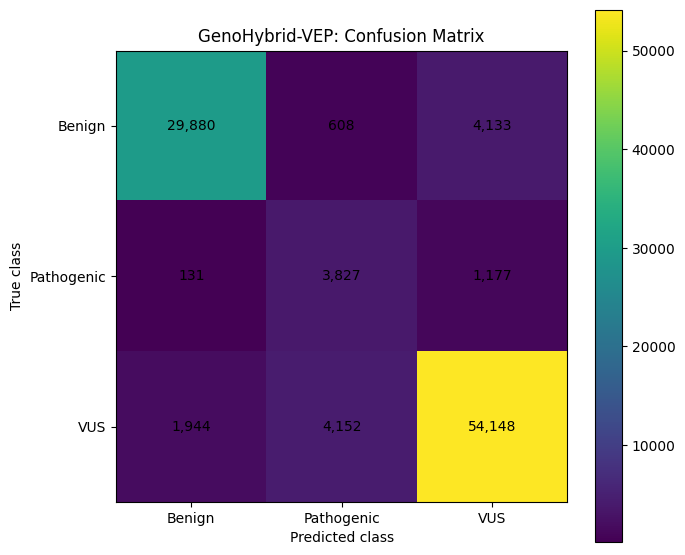

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm)

ax.set_title("GenoHybrid-VEP: Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks(range(3), CLASS_NAMES)
ax.set_yticks(range(3), CLASS_NAMES)

for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")

fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(
    FINAL_DIR / "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Row normalised confusion matrix

,Benign,Pathogenic,VUS
Benign,0.863060,0.017562,0.119378
Pathogenic,0.025511,0.745278,0.229211
VUS,0.032269,0.068920,0.898811


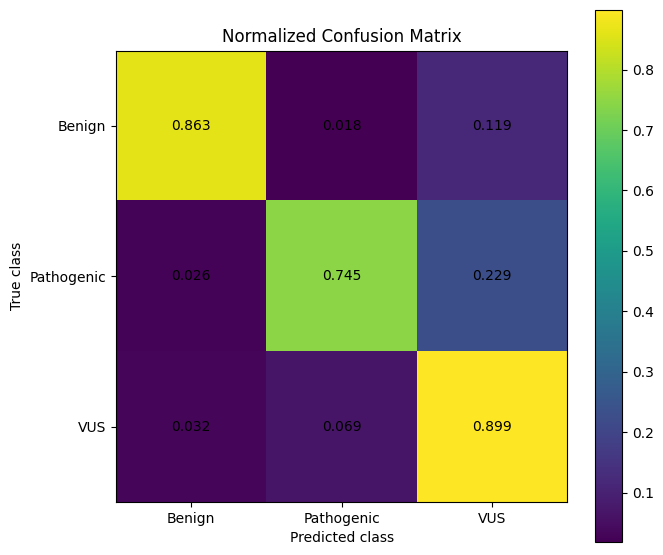

In [ ]:
cm_normalized = (
    cm.astype(np.float64)
    / cm.sum(axis=1, keepdims=True)
)

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

display(cm_normalized_df)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm_normalized)

ax.set_title("Normalized Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks(range(3), CLASS_NAMES)
ax.set_yticks(range(3), CLASS_NAMES)

for i in range(3):
    for j in range(3):
        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.3f}",
            ha="center",
            va="center"
        )

fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(
    FINAL_DIR / "final_confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### One-vs-rest Precision–Recall analysis

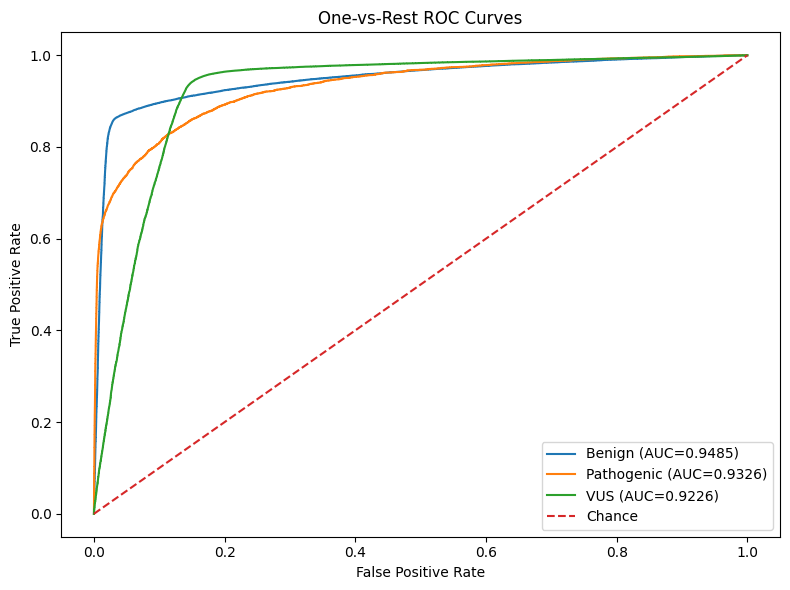

,Class,AUROC
0,Benign,0.948450
1,Pathogenic,0.932552
2,VUS,0.922646


In [ ]:
y_true_binary = label_binarize(
    y_true,
    classes=[0, 1, 2]
)

roc_rows = []

fig, ax = plt.subplots(figsize=(8, 6))

for class_index, class_name in enumerate(CLASS_NAMES):

    fpr, tpr, _ = roc_curve(
        y_true_binary[:, class_index],
        final_prob[:, class_index]
    )

    class_auc = auc(fpr, tpr)

    roc_rows.append({
        "Class": class_name,
        "AUROC": class_auc
    })

    ax.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC={class_auc:.4f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

ax.set_title("One-vs-Rest ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()

fig.tight_layout()
fig.savefig(
    FINAL_DIR / "final_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

roc_df = pd.DataFrame(roc_rows)
display(roc_df)

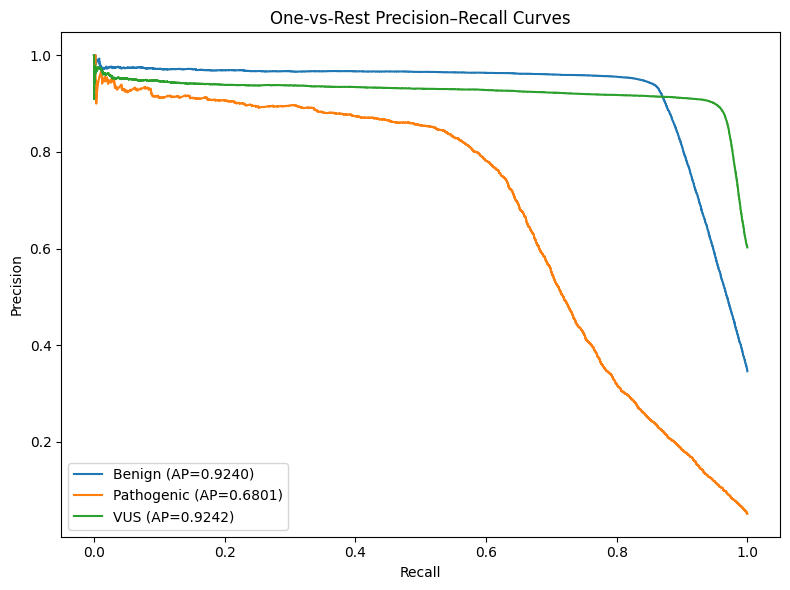

,Class,PR_AUC_AP
0,Benign,0.924014
1,Pathogenic,0.680073
2,VUS,0.924222


In [ ]:
pr_rows = []

fig, ax = plt.subplots(figsize=(8, 6))

for class_index, class_name in enumerate(CLASS_NAMES):

    precision, recall, _ = precision_recall_curve(
        y_true_binary[:, class_index],
        final_prob[:, class_index]
    )

    ap = average_precision_score(
        y_true_binary[:, class_index],
        final_prob[:, class_index]
    )

    pr_rows.append({
        "Class": class_name,
        "PR_AUC_AP": ap
    })

    ax.plot(
        recall,
        precision,
        label=f"{class_name} (AP={ap:.4f})"
    )

ax.set_title("One-vs-Rest Precision–Recall Curves")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()

fig.tight_layout()
fig.savefig(
    FINAL_DIR / "final_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

pr_df = pd.DataFrame(pr_rows)
display(pr_df)

### Per class eval table

In [ ]:
class_metric_rows = []

for class_index, class_name in enumerate(CLASS_NAMES):

    row = report_df.loc[class_name]

    class_auc = roc_auc_score(
        y_true_binary[:, class_index],
        final_prob[:, class_index]
    )

    ap = average_precision_score(
        y_true_binary[:, class_index],
        final_prob[:, class_index]
    )

    class_metric_rows.append({
        "Class": class_name,
        "Precision": row["precision"],
        "Recall": row["recall"],
        "F1": row["f1-score"],
        "Support": int(row["support"]),
        "AUROC": class_auc,
        "PR-AUC / AP": ap
    })

final_class_metrics = pd.DataFrame(class_metric_rows)

display(final_class_metrics)

final_class_metrics.to_csv(
    FINAL_DIR / "final_per_class_metrics.csv",
    index=False
)

,Class,Precision,Recall,F1,Support,AUROC,PR-AUC / AP
0,Benign,0.935065,0.863060,0.897621,34621,0.948450,0.924014
1,Pathogenic,0.445674,0.745278,0.557790,5135,0.932552,0.680073
2,VUS,0.910693,0.898811,0.904713,60244,0.922646,0.924222


# Final Saving

In [ ]:
final_report_summary = pd.DataFrame([{
    "Model": "GenoHybrid-VEP Tri-Modal",
    "Validation": "3-fold GroupKFold by gene",
    "Accuracy": overall_metrics.loc[0, "Accuracy"],
    "Balanced Accuracy": overall_metrics.loc[0, "Balanced Accuracy"],
    "Macro F1": overall_metrics.loc[0, "Macro F1"],
    "MCC": overall_metrics.loc[0, "MCC"],
    "Fusion": "Bio 0.40 / Graph 0.30 / Sequence 0.30"
}])

display(final_report_summary)

final_report_summary.to_csv(
    FINAL_DIR / "FINAL_REPORT_RESULTS.csv",
    index=False
)

print("✅ Final evaluation assets saved to:", FINAL_DIR)

,Model,Validation,Accuracy,Balanced Accuracy,Macro F1,MCC,Fusion
0,GenoHybrid-VEP Tri-Modal,3-fold GroupKFold by gene,0.87855,0.835716,0.786708,0.771052,Bio 0.40 / Graph 0.30 / Sequence 0.30


✅ Final evaluation assets saved to: /content/drive/MyDrive/variant_effect_prediction/final_validation


# EXTERNAL VALIDATION with ProteinGym clinical data : Without GeneSymbol

In [ ]:
!wget -q \
https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/clinical_ProteinGym_substitutions.zip \
-O /content/clinical_ProteinGym_substitutions.zip

!mkdir -p /content/proteingym_clinical

!unzip -q \
/content/clinical_ProteinGym_substitutions.zip \
-d /content/proteingym_clinical

print("Downloaded and extracted")

Downloaded and extracted


In [ ]:
from pathlib import Path
import pandas as pd

PG_DIR = Path(
    "/content/proteingym_clinical"
)

files = list(
    PG_DIR.rglob("*.csv")
)

print("CSV files:", len(files))

for path in files[:10]:
    print(path)

CSV files: 0


In [ ]:
sample_file = files[0]

sample_df = pd.read_csv(
    sample_file
)

print("File:", sample_file.name)
print("Shape:", sample_df.shape)

print("\nColumns:")
print(
    sample_df.columns.tolist()
)

sample_df.head()

File: NP_000034.1.csv
Shape: (21, 6)

Columns:
['Unnamed: 0', 'protein', 'protein_sequence', 'mutant', 'mutated_sequence', 'DMS_bin_score']


,Unnamed: 0,protein,protein_sequence,mutant,mutated_sequence,DMS_bin_score
0,45214,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,L7P,MLGIWTPLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Pathogenic
1,45215,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,A16T,MLGIWTLLPLVLTSVTRLSSKSVNAQVTDINSKGLELRKTVTTVET...,Benign
2,45216,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,D108G,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Pathogenic
3,45217,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,H111R,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Pathogenic
4,45218,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,T122I,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Benign


In [ ]:
for path in files:
    if "reference" in path.name.lower():
        print(path)

In [ ]:
sample_df.columns.tolist()

['Unnamed: 0',
 'protein',
 'protein_sequence',
 'mutant',
 'mutated_sequence',
 'DMS_bin_score']

In [ ]:
print(
    "Rows:",
    len(sample_df)
)

print(
    "Unique proteins:",
    sample_df["protein"].nunique()
)

print(
    "Labels:"
)

print(
    sample_df[
        "DMS_bin_score"
    ].value_counts()
)

Rows: 21
Unique proteins: 1
Labels:
DMS_bin_score
Pathogenic    16
Benign         5
Name: count, dtype: int64


## Combining SNVs across all protiens

In [ ]:
from pathlib import Path
import pandas as pd

PG_DIR = Path("/content/proteingym_clinical")

files = list(
    PG_DIR.rglob("*.csv")
)

print("CSV files found:", len(files))

all_frames = []

for path in files:

    try:
        temp = pd.read_csv(path)

        required = {
            "protein",
            "protein_sequence",
            "mutant",
            "mutated_sequence",
            "DMS_bin_score"
        }

        if required.issubset(
            temp.columns
        ):

            temp["source_file"] = path.name

            all_frames.append(
                temp
            )

    except Exception as e:
        print(
            "Skipped:",
            path.name,
            e
        )

protein_gym = pd.concat(
    all_frames,
    ignore_index=True
)

print()
print("Total clinical variants:", len(protein_gym))
print(
    "Unique proteins:",
    protein_gym["protein"].nunique()
)

print()
print("Labels:")
print(
    protein_gym[
        "DMS_bin_score"
    ].value_counts(
        dropna=False
    )
)

display(
    protein_gym.head()
)

CSV files found: 2525

Total clinical variants: 62727
Unique proteins: 2525

Labels:
DMS_bin_score
Pathogenic    32000
Benign        30727
Name: count, dtype: int64


,Unnamed: 0,protein,protein_sequence,mutant,mutated_sequence,DMS_bin_score,source_file
0,45214,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,L7P,MLGIWTPLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Pathogenic,NP_000034.1.csv
1,45215,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,A16T,MLGIWTLLPLVLTSVTRLSSKSVNAQVTDINSKGLELRKTVTTVET...,Benign,NP_000034.1.csv
2,45216,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,D108G,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Pathogenic,NP_000034.1.csv
3,45217,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,H111R,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Pathogenic,NP_000034.1.csv
4,45218,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,T122I,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Benign,NP_000034.1.csv


In [ ]:
# Cleanup
protein_gym = protein_gym[
    protein_gym[
        "DMS_bin_score"
    ].isin(
        [
            "Benign",
            "Pathogenic"
        ]
    )
].copy()

protein_gym = protein_gym.drop_duplicates(
    subset=[
        "protein",
        "mutant",
        "DMS_bin_score"
    ]
)

print(
    "Clean variants:",
    len(protein_gym)
)

print(
    "Unique proteins:",
    protein_gym[
        "protein"
    ].nunique()
)

print(
    protein_gym[
        "DMS_bin_score"
    ].value_counts()
)

Clean variants: 62727
Unique proteins: 2525
DMS_bin_score
Pathogenic    32000
Benign        30727
Name: count, dtype: int64


In [ ]:
# Validation of mutation notation
import re

pattern = re.compile(
    r"^[A-Z]\\d+[A-Z]$"
)

valid_mutation = (
    protein_gym[
        "mutant"
    ]
    .astype(str)
    .str.match(
        pattern
    )
)

print(
    "Simple substitutions:",
    valid_mutation.sum()
)

print(
    "Other formats:",
    (~valid_mutation).sum()
)

Simple substitutions: 0
Other formats: 62727


In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

PG_EXTERNAL_DIR = (
    PROJECT_DIR
    / "external_validation"
    / "proteingym"
)

RAW_COMBINED_DIR = (
    PG_EXTERNAL_DIR
    / "raw_combined"
)

MAPPED_DIR = (
    PG_EXTERNAL_DIR
    / "mapped"
)

BENCHMARK_DIR = (
    PG_EXTERNAL_DIR
    / "benchmark"
)

for folder in [
    RAW_COMBINED_DIR,
    MAPPED_DIR,
    BENCHMARK_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("ProteinGym external-validation folders created:")
print(PG_EXTERNAL_DIR)

ProteinGym external-validation folders created:
/content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym


In [ ]:
clean_path = (
    RAW_COMBINED_DIR
    / "proteingym_clinical_clean.csv"
)

protein_gym.to_csv(
    clean_path,
    index=False
)

print(
    "✅ Saved clean ProteinGym restore point:"
)

print(
    clean_path
)

print(
    "Rows:",
    len(protein_gym)
)

print(
    "Unique proteins:",
    protein_gym["protein"].nunique()
)

✅ Saved clean ProteinGym restore point:
/content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/raw_combined/proteingym_clinical_clean.csv
Rows: 62727
Unique proteins: 2525


In [ ]:
parquet_path = (
    RAW_COMBINED_DIR
    / "proteingym_clinical_clean.parquet"
)

protein_gym.to_parquet(
    parquet_path,
    index=False
)

print(
    "✅ Parquet restore point saved:",
    parquet_path
)

✅ Parquet restore point saved: /content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/raw_combined/proteingym_clinical_clean.parquet


## RESTORE POINT

In [ ]:
from google.colab import drive
import os

if not os.path.exists('content/drive/MyDrive/'):
    drive.mount('/content/drive')
    print("✅ Drive mounted")
else:
    print("✅ Drive already mounted")

Mounted at /content/drive
✅ Drive mounted


In [ ]:
from pathlib import Path
import pandas as pd
import requests
import re
import time
import json

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

PG_DIR = (
    PROJECT_DIR
    / "external_validation"
    / "proteingym"
)

RAW_DIR = PG_DIR / "raw_combined"
MAPPED_DIR = PG_DIR / "mapped"
CACHE_DIR = PG_DIR / "mapping_cache"

MAPPED_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Reload our restore point
protein_gym = pd.read_parquet(
    RAW_DIR / "proteingym_clinical_clean.parquet"
)

print("Rows:", len(protein_gym))
print("Proteins:", protein_gym["protein"].nunique())

Rows: 62727
Proteins: 2525


In [ ]:
display(protein_gym.head())

,Unnamed: 0,protein,protein_sequence,mutant,mutated_sequence,DMS_bin_score,source_file
0,45214,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,L7P,MLGIWTPLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Pathogenic,NP_000034.1.csv
1,45215,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,A16T,MLGIWTLLPLVLTSVTRLSSKSVNAQVTDINSKGLELRKTVTTVET...,Benign,NP_000034.1.csv
2,45216,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,D108G,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Pathogenic,NP_000034.1.csv
3,45217,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,H111R,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Pathogenic,NP_000034.1.csv
4,45218,NP_000034.1,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,T122I,MLGIWTLLPLVLTSVARLSSKSVNAQVTDINSKGLELRKTVTTVET...,Benign,NP_000034.1.csv


## Protein mapping

In [ ]:
AA3 = {
    "A": "Ala", "R": "Arg", "N": "Asn", "D": "Asp",
    "C": "Cys", "Q": "Gln", "E": "Glu", "G": "Gly",
    "H": "His", "I": "Ile", "L": "Leu", "K": "Lys",
    "M": "Met", "F": "Phe", "P": "Pro", "S": "Ser",
    "T": "Thr", "W": "Trp", "Y": "Tyr", "V": "Val"
}

pattern = re.compile(r"^([A-Z])(\d+)([A-Z])$")


def make_hgvs(protein, mutant):
    m = pattern.match(str(mutant))

    if not m:
        return None

    ref, pos, alt = m.groups()

    if ref not in AA3 or alt not in AA3:
        return None

    return (
        f"{protein}:p."
        f"{AA3[ref]}{pos}{AA3[alt]}"
    )


protein_gym["protein_hgvs"] = [
    make_hgvs(p, m)
    for p, m in zip(
        protein_gym["protein"],
        protein_gym["mutant"]
    )
]

print(
    protein_gym["protein_hgvs"]
    .notna()
    .value_counts()
)

display(
    protein_gym[
        [
            "protein",
            "mutant",
            "protein_hgvs",
            "DMS_bin_score"
        ]
    ].head()
)

protein_hgvs
True    62727
Name: count, dtype: int64


,protein,mutant,protein_hgvs,DMS_bin_score
0,NP_000034.1,L7P,NP_000034.1:p.Leu7Pro,Pathogenic
1,NP_000034.1,A16T,NP_000034.1:p.Ala16Thr,Benign
2,NP_000034.1,D108G,NP_000034.1:p.Asp108Gly,Pathogenic
3,NP_000034.1,H111R,NP_000034.1:p.His111Arg,Pathogenic
4,NP_000034.1,T122I,NP_000034.1:p.Thr122Ile,Benign


In [ ]:
test_variants = (
    protein_gym["protein_hgvs"]
    .dropna()
    .head(10)
    .tolist()
)

test_variants

['NP_000034.1:p.Leu7Pro',
 'NP_000034.1:p.Ala16Thr',
 'NP_000034.1:p.Asp108Gly',
 'NP_000034.1:p.His111Arg',
 'NP_000034.1:p.Thr122Ile',
 'NP_000034.1:p.Cys135Tyr',
 'NP_000034.1:p.Asp144Asn',
 'NP_000034.1:p.Ile184Val',
 'NP_000034.1:p.Arg250Gln',
 'NP_000034.1:p.Arg250Pro']

## Loading Ensembl

In [ ]:
ENSEMBL_URL = (
    "https://rest.ensembl.org/"
    "variant_recoder/homo_sapiens"
)


def recode_batch(variants):
    headers = {
        "Content-Type": "application/json",
        "Accept": "application/json"
    }

    payload = {
        "ids": variants
    }

    params = {
        "fields": "hgvsg,hgvsc,hgvsp,spdi",
        "vcf_string": 1,
        "minimal": 1
    }

    response = requests.post(
        ENSEMBL_URL,
        headers=headers,
        params=params,
        json=payload,
        timeout=120
    )

    print("HTTP:", response.status_code)

    if response.status_code != 200:
        print(response.text[:2000])
        return None

    return response.json()

In [ ]:
test_result = recode_batch(test_variants)
print(json.dumps(test_result, indent=2)[:15000])

HTTP: 200
[
  {
    "C": {
      "hgvsp": [
        "ENSP00000347426.2:p.Leu7Pro",
        "ENSP00000347979.3:p.Leu7Pro",
        "ENSP00000349896.2:p.Leu7Pro",
        "ENSP00000424113.1:p.Leu7Pro",
        "ENSP00000420975.1:p.Leu7Pro",
        "ENSP00000425159.1:p.Leu7Pro",
        "ENSP00000422453.1:p.Leu7Pro",
        "ENSP00000423755.1:p.Leu7Pro",
        "ENSP00000477997.3:p.Leu7Pro",
        "ENSP00000498466.1:p.Leu7Pro",
        "ENSP00000512859.1:p.Leu7Pro",
        "ENSP00000512861.1:p.Leu7Pro",
        "ENSP00000512862.1:p.Leu7Pro",
        "ENSP00000512863.1:p.Leu7Pro",
        "ENSP00000512864.1:p.Leu7Pro",
        "ENSP00000512865.1:p.Leu7Pro",
        "ENSP00000513028.1:p.Leu7Pro",
        "ENSP00000513059.1:p.Leu7Pro",
        "ENSP00000513060.1:p.Leu7Pro",
        "ENSP00000513104.1:p.Leu7Pro",
        "ENSP00000815193.1:p.Leu7Pro",
        "NP_000034.1:p.Leu7Pro",
        "NP_001307548.1:p.Leu7Pro",
        "NP_690610.1:p.Leu7Pro",
        "NP_690611.1:p.Leu7Pro"
   

## Bulk processing

In [ ]:
import pandas as pd
import requests
import time
import json
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

PG_DIR = PROJECT_DIR / "external_validation" / "proteingym"
CACHE_DIR = PG_DIR / "mapping_cache"
MAPPED_DIR = PG_DIR / "mapped"

CACHE_DIR.mkdir(parents=True, exist_ok=True)
MAPPED_DIR.mkdir(parents=True, exist_ok=True)

ENSEMBL_URL = (
    "https://rest.ensembl.org/"
    "variant_recoder/homo_sapiens"
)

In [ ]:
def recode_batch(variants, retries=5):

    headers = {
        "Content-Type": "application/json",
        "Accept": "application/json"
    }

    payload = {
        "ids": variants
    }

    params = {
        "fields": "hgvsg,hgvsc,hgvsp,spdi",
        "vcf_string": 1,
        "minimal": 1
    }

    for attempt in range(retries):

        try:
            r = requests.post(
                ENSEMBL_URL,
                headers=headers,
                params=params,
                json=payload,
                timeout=120
            )

            if r.status_code == 200:
                return r.json()

            if r.status_code == 429:
                wait = int(
                    r.headers.get(
                        "Retry-After",
                        10
                    )
                )

                print(
                    f"Rate limited. Waiting {wait}s..."
                )

                time.sleep(wait)
                continue

            print(
                "HTTP error:",
                r.status_code,
                r.text[:300]
            )

        except Exception as e:
            print(
                "Request failed:",
                e
            )

        time.sleep(
            5 * (attempt + 1)
        )

    return None

In [ ]:
VALID_CHROMS = {
    str(i)
    for i in range(1, 23)
} | {"X", "Y"}


def parse_recoder_entry(entry):

    results = []

    if not isinstance(entry, dict):
        return results

    for _, block in entry.items():

        if not isinstance(block, dict):
            continue

        input_hgvs = block.get(
            "input"
        )

        vcf_entries = block.get(
            "vcf_string",
            []
        )

        if isinstance(
            vcf_entries,
            str
        ):
            vcf_entries = [
                vcf_entries
            ]

        for vcf in vcf_entries:

            parts = vcf.split("-")

            if len(parts) != 4:
                continue

            chrom, pos, ref, alt = parts

            # Ignore LRG and other non-primary references
            if chrom not in VALID_CHROMS:
                continue

            # SNVs only
            if (
                len(ref) != 1
                or len(alt) != 1
            ):
                continue

            if ref not in "ACGT":
                continue

            if alt not in "ACGT":
                continue

            results.append(
                {
                    "protein_hgvs":
                        input_hgvs,

                    "chrom":
                        chrom,

                    "pos":
                        int(pos),

                    "ref":
                        ref,

                    "alt":
                        alt,

                    "variant_key":
                        f"{chrom}:{pos}:{ref}>{alt}"
                }
            )

    return results

In [ ]:
parsed = []

for entry in test_result:

    parsed.extend(
        parse_recoder_entry(
            entry
        )
    )

test_mapped = pd.DataFrame(
    parsed
)

display(
    test_mapped
)

,protein_hgvs,chrom,pos,ref,alt,variant_key
0,NP_000034.1:p.Leu7Pro,10,88990896,T,C,10:88990896:T>C
1,NP_000034.1:p.Ala16Thr,10,89003044,G,A,10:89003044:G>A
2,NP_000034.1:p.Asp108Gly,10,89007826,A,G,10:89007826:A>G
3,NP_000034.1:p.His111Arg,10,89007835,A,G,10:89007835:A>G
4,NP_000034.1:p.Thr122Ile,10,89008919,C,T,10:89008919:C>T
5,NP_000034.1:p.Cys135Tyr,10,89008958,G,A,10:89008958:G>A
6,NP_000034.1:p.Asp144Asn,10,89008984,G,A,10:89008984:G>A
7,NP_000034.1:p.Ile184Val,10,89010797,A,G,10:89010797:A>G
8,NP_000034.1:p.Arg250Gln,10,89014191,G,A,10:89014191:G>A
9,NP_000034.1:p.Arg250Pro,10,89014191,G,C,10:89014191:G>C


In [ ]:
BATCH_SIZE = 100

mapping_input = (
    protein_gym[
        protein_gym["protein_hgvs"].notna()
    ]
    .copy()
)

unique_hgvs = (
    mapping_input[
        "protein_hgvs"
    ]
    .drop_duplicates()
    .tolist()
)

print(
    "Unique HGVS variants:",
    len(unique_hgvs)
)

Unique HGVS variants: 62727


### Using bulk mapper

In [ ]:
import time
import json
import requests
import pandas as pd
from pathlib import Path

BATCH_SIZE = 50
MAX_RETRIES = 6

FAILED_BATCHES_FILE = (
    CACHE_DIR / "failed_batches.json"
)

ENSEMBL_URL = (
    "https://rest.ensembl.org/"
    "variant_recoder/homo_sapiens"
)


def recode_batch(variants, retries=MAX_RETRIES):

    headers = {
        "Content-Type": "application/json",
        "Accept": "application/json"
    }

    payload = {
        "ids": variants
    }

    params = {
        "fields": "hgvsg,hgvsc,hgvsp,spdi",
        "vcf_string": 1,
        "minimal": 1
    }

    for attempt in range(retries):

        try:
            r = requests.post(
                ENSEMBL_URL,
                headers=headers,
                params=params,
                json=payload,
                timeout=180
            )

            if r.status_code == 200:
                return r.json()

            if r.status_code == 429:

                wait = int(
                    r.headers.get(
                        "Retry-After",
                        15
                    )
                )

                print(
                    f"429 rate limit. "
                    f"Waiting {wait}s..."
                )

                time.sleep(wait)
                continue

            print(
                f"HTTP {r.status_code} "
                f"on attempt {attempt + 1}"
            )

        except requests.exceptions.ReadTimeout:

            wait = min(
                15 * (attempt + 1),
                90
            )

            print(
                f"Read timeout "
                f"(attempt {attempt + 1}/{retries}) "
                f"→ waiting {wait}s"
            )

            time.sleep(wait)

        except requests.exceptions.RequestException as e:

            wait = min(
                10 * (attempt + 1),
                60
            )

            print(
                f"Network error "
                f"(attempt {attempt + 1}/{retries}): "
                f"{e}"
            )

            time.sleep(wait)

    return None

In [ ]:
all_mappings = []
failed_batches = []
MAX_BATCHES = 20

num_batches = min((len(unique_hgvs) + BATCH_SIZE - 1) // BATCH_SIZE, MAX_BATCHES)

print("Total variants:", len(unique_hgvs))
print("Total batches:", num_batches)

for batch_idx in range(num_batches):
    start = (batch_idx * BATCH_SIZE)
    end = min(start + BATCH_SIZE, len(unique_hgvs))
    batch = unique_hgvs[start:end]
    cache_file = (CACHE_DIR / f"batch_{batch_idx:05d}.json")

    # --------------------------
    # Resume from saved cache
    # --------------------------

    if cache_file.exists():
        with open(cache_file, "r") as f:
            result = json.load(f)
    else:
        print(f"\nRequesting "f"batch {batch_idx + 1}/{num_batches}"        )
        result = recode_batch(batch)
        if result is None:
            print(f"❌ Batch {batch_idx} failed")
            failed_batches.append(
                {
                    "batch_idx": batch_idx,
                    "start": start,
                    "end": end
                }
            )

            # save failed list immediately
            with open(FAILED_BATCHES_FILE, "w") as f:
                json.dump(
                    failed_batches,
                    f,
                    indent=2
                )
            continue
        # save successful API response
        with open(cache_file, "w") as f:
            json.dump(
                result,
                f
            )
        time.sleep(0.5)

    # --------------------------
    # Parse successful response
    # --------------------------

    for entry in result:
        all_mappings.extend(parse_recoder_entry(entry))
    if (
        (batch_idx + 1) % 10 == 0
        or batch_idx == 0
        or batch_idx == num_batches - 1
    ):

        print(
            f"Progress: "
            f"{batch_idx + 1}/{num_batches}"
            f" | mappings: {len(all_mappings)}"
            f" | failed: {len(failed_batches)}"
        )

Total variants: 62727
Total batches: 20
Progress: 1/20 | mappings: 111 | failed: 0

Requesting batch 6/20
Read timeout (attempt 1/6) → waiting 15s
Read timeout (attempt 2/6) → waiting 30s
Read timeout (attempt 3/6) → waiting 45s

Requesting batch 7/20
Read timeout (attempt 1/6) → waiting 15s

Requesting batch 8/20

Requesting batch 9/20

Requesting batch 10/20
Progress: 10/20 | mappings: 672 | failed: 0

Requesting batch 11/20

Requesting batch 12/20

Requesting batch 13/20

Requesting batch 14/20

Requesting batch 15/20

Requesting batch 16/20

Requesting batch 17/20

Requesting batch 18/20
Read timeout (attempt 1/6) → waiting 15s
Read timeout (attempt 2/6) → waiting 30s
HTTP 500 on attempt 3
HTTP 500 on attempt 4
HTTP 500 on attempt 5
HTTP 500 on attempt 6
❌ Batch 17 failed

Requesting batch 19/20
Read timeout (attempt 1/6) → waiting 15s
Read timeout (attempt 2/6) → waiting 30s

Requesting batch 20/20
Progress: 20/20 | mappings: 1195 | failed: 1


In [ ]:
mapped_df = pd.DataFrame(all_mappings)

print("Mapped genomic SNVs:", len(mapped_df))
print("Unique genomic variants:", mapped_df["variant_key"].nunique())
print("Unique protein HGVS mapped:", mapped_df["protein_hgvs"].nunique())

Mapped genomic SNVs: 1195
Unique genomic variants: 1081
Unique protein HGVS mapped: 950


In [ ]:
mapped_df = mapped_df.merge(
    protein_gym[
        [
            "protein",
            "mutant",
            "protein_hgvs",
            "DMS_bin_score"
        ]
    ],
    on="protein_hgvs",
    how="left"
)

mapped_df.head()

,protein_hgvs,chrom,pos,ref,alt,variant_key,protein,mutant,DMS_bin_score
0,NP_000034.1:p.Leu7Pro,10,88990896,T,C,10:88990896:T>C,NP_000034.1,L7P,Pathogenic
1,NP_000034.1:p.Ala16Thr,10,89003044,G,A,10:89003044:G>A,NP_000034.1,A16T,Benign
2,NP_000034.1:p.Asp108Gly,10,89007826,A,G,10:89007826:A>G,NP_000034.1,D108G,Pathogenic
3,NP_000034.1:p.His111Arg,10,89007835,A,G,10:89007835:A>G,NP_000034.1,H111R,Pathogenic
4,NP_000034.1:p.Thr122Ile,10,89008919,C,T,10:89008919:C>T,NP_000034.1,T122I,Benign


In [ ]:
# Saving restore point

mapped_path = (MAPPED_DIR / "proteingym_grch38_snvs_unverified.parquet")
mapped_df.to_parquet(mapped_path, index=False)
mapped_df.to_csv(MAPPED_DIR / "proteingym_grch38_snvs_unverified.csv", index=False)
print("✅ Saved:", mapped_path)

✅ Saved: /content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/mapped/proteingym_grch38_snvs_unverified.parquet


## Continuing ...

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

PG_DIR = PROJECT_DIR / "external_validation" / "proteingym"

MAPPED_DIR = PG_DIR / "mapped"
BENCHMARK_DIR = PG_DIR / "benchmark"

BENCHMARK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

mapped_df = pd.read_parquet(
    MAPPED_DIR / "proteingym_grch38_snvs_unverified.parquet"
)

print("Loaded rows:", len(mapped_df))
print("Unique variants:", mapped_df["variant_key"].nunique())

display(mapped_df.head())

Loaded rows: 1195
Unique variants: 1081


,protein_hgvs,chrom,pos,ref,alt,variant_key,protein,mutant,DMS_bin_score
0,NP_000034.1:p.Leu7Pro,10,88990896,T,C,10:88990896:T>C,NP_000034.1,L7P,Pathogenic
1,NP_000034.1:p.Ala16Thr,10,89003044,G,A,10:89003044:G>A,NP_000034.1,A16T,Benign
2,NP_000034.1:p.Asp108Gly,10,89007826,A,G,10:89007826:A>G,NP_000034.1,D108G,Pathogenic
3,NP_000034.1:p.His111Arg,10,89007835,A,G,10:89007835:A>G,NP_000034.1,H111R,Pathogenic
4,NP_000034.1:p.Thr122Ile,10,89008919,C,T,10:89008919:C>T,NP_000034.1,T122I,Benign


In [ ]:
mapping_counts = (
    mapped_df
    .groupby("protein_hgvs")["variant_key"]
    .nunique()
)

unique_hgvs = mapping_counts[
    mapping_counts == 1
].index

clean_map = mapped_df[
    mapped_df["protein_hgvs"].isin(
        unique_hgvs
    )
].copy()

clean_map = clean_map.drop_duplicates(
    subset=[
        "protein_hgvs",
        "variant_key"
    ]
)

print("Before:", len(mapped_df))
print("After unique mapping filter:", len(clean_map))

print(
    "Unique ProteinGym variants:",
    clean_map["protein_hgvs"].nunique()
)

Before: 1195
After unique mapping filter: 843
Unique ProteinGym variants: 843


In [ ]:
!pip -q install py2bit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 2.4 MB/s eta 0:00:00


In [ ]:
import py2bit

HG38_PATH = (
    PROJECT_DIR
    / "data"
    / "references"
    / "hg38.2bit"
)

print(HG38_PATH)
print("Exists:", HG38_PATH.exists())

/content/drive/MyDrive/variant_effect_prediction/data/references/hg38.2bit
Exists: True


## Validating

In [ ]:
tb = py2bit.open(
    str(HG38_PATH)
)

def check_ref(row):
    chrom = str(row["chrom"])
    pos = int(row["pos"])
    ref = str(row["ref"]).upper()

    possible_chroms = [
        chrom,
        f"chr{chrom}"
    ]

    for c in possible_chroms:
        try:
            genome_base = tb.sequence(
                c,
                pos - 1,
                pos
            ).upper()

            return genome_base == ref

        except Exception:
            continue

    return False


clean_map["ref_matches_hg38"] = (
    clean_map.apply(
        check_ref,
        axis=1
    )
)

print(
    clean_map[
        "ref_matches_hg38"
    ].value_counts()
)

ref_matches_hg38
True    843
Name: count, dtype: int64


In [ ]:
verified = clean_map[
    clean_map["ref_matches_hg38"]
].copy()

print(
    "Verified GRCh38 SNVs:",
    len(verified)
)

Verified GRCh38 SNVs: 843


## Removing training set overlap

In [ ]:
FEATURES_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "genohybrid_features.parquet"
)

training_df = pd.read_parquet(
    FEATURES_PATH
)

print(
    "Training rows:",
    len(training_df)
)

Training rows: 100000


In [ ]:
training_keys = set(
    training_df[
        "variant_key"
    ]
    .astype(str)
)

verified["seen_in_training"] = (
    verified["variant_key"]
    .astype(str)
    .isin(training_keys)
)

print(
    verified[
        "seen_in_training"
    ].value_counts()
)

seen_in_training
False    820
True      23
Name: count, dtype: int64


In [ ]:
external = verified[
    ~verified["seen_in_training"]
].copy()

print(
    "Final independent variants:",
    len(external)
)

print()
print(
    external[
        "DMS_bin_score"
    ].value_counts()
)

Final independent variants: 820

DMS_bin_score
Pathogenic    448
Benign        372
Name: count, dtype: int64


## Saving benchmark CSV

In [ ]:
final_csv = (
    BENCHMARK_DIR
    / "proteingym_external_benchmark.csv"
)

external.to_csv(
    final_csv,
    index=False
)

external.to_parquet(
    BENCHMARK_DIR
    / "proteingym_external_benchmark.parquet",
    index=False
)

print(
    "Saved:",
    final_csv
)

Saved: /content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/benchmark/proteingym_external_benchmark.csv


## Creating VCF for predictor

In [ ]:
vcf_path = (
    BENCHMARK_DIR
    / "proteingym_external_benchmark.vcf"
)

with open(
    vcf_path,
    "w"
) as f:

    f.write(
        "##fileformat=VCFv4.2\n"
    )

    f.write(
        "##reference=GRCh38\n"
    )

    f.write(
        "#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO\n"
    )

    for i, row in external.reset_index(
        drop=True
    ).iterrows():

        variant_id = (
            f"PG_{i}"
        )

        f.write(
            f"{row['chrom']}\t"
            f"{int(row['pos'])}\t"
            f"{variant_id}\t"
            f"{row['ref']}\t"
            f"{row['alt']}\t"
            f".\t"
            f"PASS\t"
            f".\n"
        )

print(
    "VCF created:",
    vcf_path
)

VCF created: /content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/benchmark/proteingym_external_benchmark.vcf


In [ ]:
!pip install pysam pyBigWig torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 806.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 189.1/189.1 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 61.2 MB/s eta 0:00:00


In [ ]:
!python "/content/drive/MyDrive/variant_effect_prediction/predict.py" \
  --vcf "/content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/benchmark/proteingym_external_benchmark.vcf" \
  --output "/content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/benchmark/proteingym_predictions.csv" \
  --project-dir "/content/drive/MyDrive/variant_effect_prediction"

Device: cpu
Loading processed training features...
Reproduced development training rows: 80065
Models loaded.
Parsing VCF and generating features...
[W::vcf_parse] Contig '10' is not defined in the header. (Quick workaround: index the file with tabix.)
[W::vcf_parse] Missing headers may cause later processing to fail
[W::vcf_parse] Contig '5' is not defined in the header. (Quick workaround: index the file with tabix.)
[W::vcf_parse] Missing headers may cause later processing to fail
[W::vcf_parse] Contig '9' is not defined in the header. (Quick workaround: index the file with tabix.)
[W::vcf_parse] Missing headers may cause later processing to fail
[W::vcf_parse] Contig '16' is not defined in the header. (Quick workaround: index the file with tabix.)
[W::vcf_parse] Missing headers may cause later processing to fail
[W::vcf_parse] Contig '18' is not defined in the header. (Quick workaround: index the file with tabix.)
[W::vcf_parse] Missing headers may cause later processing to fail
[W:

In [ ]:
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

BENCHMARK_DIR = (
    PROJECT_DIR
    / "external_validation"
    / "proteingym"
    / "benchmark"
)

truth = pd.read_csv(
    BENCHMARK_DIR
    / "proteingym_external_benchmark.csv"
)

pred = pd.read_csv(
    BENCHMARK_DIR
    / "proteingym_predictions.csv"
)

print("Truth rows:", len(truth))
print("Prediction rows:", len(pred))
print()

print("Prediction columns:")
print(pred.columns.tolist())

Truth rows: 820
Prediction rows: 820

Prediction columns:
['Chromosome', 'Start', 'ReferenceAlleleVCF', 'AlternateAlleleVCF', 'variant_key', 'GeneSymbol', 'molecular_consequence_raw', 'consequence_category', 'phylop', 'phastcons', 'status', 'seq_prob_benign', 'seq_prob_pathogenic', 'seq_prob_vus', 'bio_prob_benign', 'bio_prob_pathogenic', 'bio_prob_vus', 'graph_prob_benign', 'graph_prob_pathogenic', 'graph_prob_vus', 'final_prob_benign', 'final_prob_pathogenic', 'final_prob_vus', 'predicted_label', 'predicted_class', 'confidence']


In [ ]:
print(
    "variant_key in truth:",
    "variant_key" in truth.columns
)

print(
    "variant_key in pred:",
    "variant_key" in pred.columns
)

variant_key in truth: True
variant_key in pred: True


In [ ]:
merged = truth.merge(
    pred,
    on="variant_key",
    how="inner",
    suffixes=("_truth", "_pred")
)

In [ ]:
print(
    "Matched benchmark variants:",
    len(merged)
)

print()
print(
    merged["DMS_bin_score"]
    .value_counts()
)

print()
print(
    merged["predicted_class"]
    .value_counts()
)

Matched benchmark variants: 820

DMS_bin_score
Pathogenic    448
Benign        372
Name: count, dtype: int64

predicted_class
Pathogenic    528
Benign        292
Name: count, dtype: int64


In [ ]:
truth_map = {
    "Benign": 0,
    "Pathogenic": 1
}

pred_map = {
    "Benign": 0,
    "Pathogenic": 1,
    "VUS": 2
}

merged["y_true"] = (
    merged["DMS_bin_score"]
    .map(truth_map)
)

merged["y_pred"] = (
    merged["predicted_class"]
    .map(pred_map)
)

In [ ]:
print(
    merged[
        ["DMS_bin_score", "predicted_class"]
    ]
    .drop_duplicates()
)

   DMS_bin_score predicted_class
0     Pathogenic          Benign
1         Benign          Benign
2     Pathogenic      Pathogenic
27        Benign      Pathogenic


In [ ]:
binary = merged[
    merged["y_pred"].isin([0, 1])
].copy()

coverage = (
    len(binary)
    / len(merged)
)

print(
    f"Coverage: {coverage:.4f}"
)

print(
    f"Abstention/VUS rate: {1 - coverage:.4f}"
)

print()

print(
    "Accuracy:",
    accuracy_score(
        binary["y_true"],
        binary["y_pred"]
    )
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(
        binary["y_true"],
        binary["y_pred"]
    )
)

print(
    "Macro F1:",
    f1_score(
        binary["y_true"],
        binary["y_pred"],
        average="macro"
    )
)

print(
    "MCC:",
    matthews_corrcoef(
        binary["y_true"],
        binary["y_pred"]
    )
)

print()
print(
    classification_report(
        binary["y_true"],
        binary["y_pred"],
        target_names=[
            "Benign",
            "Pathogenic"
        ],
        digits=4
    )
)

print(
    "Confusion matrix:"
)

print(
    confusion_matrix(
        binary["y_true"],
        binary["y_pred"]
    )
)

Coverage: 1.0000
Abstention/VUS rate: 0.0000

Accuracy: 0.7073170731707317
Balanced Accuracy: 0.6956605222734256
Macro F1: 0.6963262887616037
MCC: 0.40685091219555475

              precision    recall  f1-score   support

      Benign     0.7260    0.5699    0.6386       372
  Pathogenic     0.6970    0.8214    0.7541       448

    accuracy                         0.7073       820
   macro avg     0.7115    0.6957    0.6963       820
weighted avg     0.7102    0.7073    0.7017       820

Confusion matrix:
[[212 160]
 [ 80 368]]


## External Validation: With GeneSymbol and Consequence

In [ ]:
from pathlib import Path
import pandas as pd
import requests
import time
import json

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

BENCHMARK_DIR = (
    PROJECT_DIR
    / "external_validation"
    / "proteingym"
    / "benchmark"
)

benchmark = pd.read_csv(
    BENCHMARK_DIR / "proteingym_external_benchmark.csv"
)

print("Variants:", len(benchmark))
display(benchmark.head())

Variants: 820


,protein_hgvs,chrom,pos,ref,alt,variant_key,protein,mutant,DMS_bin_score,ref_matches_hg38,seen_in_training
0,NP_000034.1:p.Leu7Pro,10,88990896,T,C,10:88990896:T>C,NP_000034.1,L7P,Pathogenic,True,False
1,NP_000034.1:p.Ala16Thr,10,89003044,G,A,10:89003044:G>A,NP_000034.1,A16T,Benign,True,False
2,NP_000034.1:p.Asp108Gly,10,89007826,A,G,10:89007826:A>G,NP_000034.1,D108G,Pathogenic,True,False
3,NP_000034.1:p.His111Arg,10,89007835,A,G,10:89007835:A>G,NP_000034.1,H111R,Pathogenic,True,False
4,NP_000034.1:p.Thr122Ile,10,89008919,C,T,10:89008919:C>T,NP_000034.1,T122I,Benign,True,False


In [ ]:
VEP_URL = (
    "https://rest.ensembl.org/"
    "vep/homo_sapiens/region"
)

BATCH_SIZE = 100


def query_vep_batch(variants, retries=5):

    headers = {
        "Content-Type": "application/json",
        "Accept": "application/json"
    }

    payload = {
        "variants": variants
    }

    for attempt in range(retries):

        try:
            r = requests.post(
                VEP_URL,
                headers=headers,
                json=payload,
                timeout=120
            )

            if r.status_code == 200:
                return r.json()

            if r.status_code == 429:
                wait = int(
                    r.headers.get(
                        "Retry-After",
                        10
                    )
                )

                print(
                    f"Rate limited → waiting {wait}s"
                )

                time.sleep(wait)
                continue

            print(
                f"HTTP {r.status_code}"
            )

        except requests.exceptions.RequestException as e:

            print(
                f"Attempt {attempt + 1} failed:",
                e
            )

        time.sleep(
            10 * (attempt + 1)
        )

    return None

In [ ]:
def make_vep_input(row):
    return (
        f"{row['chrom']} "
        f"{int(row['pos'])} "
        f". "
        f"{row['ref']} "
        f"{row['alt']} "
        f". . ."
    )

benchmark["vep_input"] = benchmark.apply(
    make_vep_input,
    axis=1
)

benchmark[
    ["variant_key", "vep_input"]
].head()

,variant_key,vep_input
0,10:88990896:T>C,10 88990896 . T C . . .
1,10:89003044:G>A,10 89003044 . G A . . .
2,10:89007826:A>G,10 89007826 . A G . . .
3,10:89007835:A>G,10 89007835 . A G . . .
4,10:89008919:C>T,10 89008919 . C T . . .


In [ ]:
test_batch = (
    benchmark[
        "vep_input"
    ]
    .head(5)
    .tolist()
)

test_result = query_vep_batch(
    test_batch
)

print(
    json.dumps(
        test_result,
        indent=2
    )[:10000]
)

[
  {
    "id": ".",
    "strand": 1,
    "transcript_consequences": [
      {
        "distance": 392,
        "strand": 1,
        "impact": "MODIFIER",
        "consequence_terms": [
          "upstream_gene_variant"
        ],
        "biotype": "protein_coding_CDS_not_defined",
        "gene_symbol": "FAS",
        "hgnc_id": "HGNC:11920",
        "variant_allele": "C",
        "gene_id": "ENSG00000026103",
        "gene_symbol_source": "HGNC",
        "transcript_id": "ENST00000313771"
      },
      {
        "consequence_terms": [
          "missense_variant"
        ],
        "strand": 1,
        "protein_start": 7,
        "impact": "MODERATE",
        "sift_prediction": "deleterious",
        "sift_score": 0,
        "gene_id": "ENSG00000026103",
        "cdna_start": 20,
        "amino_acids": "L/P",
        "cdna_end": 20,
        "cds_start": 20,
        "gene_symbol": "FAS",
        "protein_end": 7,
        "biotype": "protein_coding",
        "codons": "cTc/cCc",
    

In [ ]:
def parse_mutant(mutant):
    """
    Example:
    L7P -> ('L', 7, 'P')
    """
    import re

    m = re.match(
        r"^([A-Z])(\d+)([A-Z])$",
        str(mutant)
    )

    if not m:
        return None

    return (
        m.group(1),
        int(m.group(2)),
        m.group(3)
    )

In [ ]:
def choose_best_vep_consequence(
    vep_entry,
    expected_mutant=None
):
    """
    Select the transcript consequence that best matches
    the ProteinGym amino-acid substitution.
    """

    transcripts = (
        vep_entry.get(
            "transcript_consequences",
            []
        )
        or []
    )

    parsed_mut = (
        parse_mutant(expected_mutant)
        if expected_mutant
        else None
    )

    candidates = []

    for tc in transcripts:

        consequences = (
            tc.get(
                "consequence_terms",
                []
            )
            or []
        )

        biotype = tc.get("biotype")
        aa_change = tc.get("amino_acids")

        # We care about coding missense substitutions
        if "missense_variant" not in consequences:
            continue

        if biotype not in {
            "protein_coding",
            "nonsense_mediated_decay"
        }:
            continue

        score = 0

        # Prefer normal protein-coding transcript
        if biotype == "protein_coding":
            score += 5

        # Match ProteinGym amino-acid change
        if parsed_mut and aa_change:

            ref_aa, _, alt_aa = parsed_mut

            expected_aa = (
                f"{ref_aa}/{alt_aa}"
            )

            if aa_change == expected_aa:
                score += 20

        # Prefer exact protein position where available
        if parsed_mut:

            _, expected_pos, _ = parsed_mut

            protein_start = tc.get(
                "protein_start"
            )

            if protein_start == expected_pos:
                score += 10

        if tc.get("gene_symbol"):
            score += 2

        candidates.append(
            (
                score,
                tc
            )
        )

    if not candidates:
        return {
            "gene_symbol": None,
            "consequence": None,
            "transcript_id": None,
            "amino_acids": None,
            "protein_position": None
        }

    candidates.sort(
        key=lambda x: x[0],
        reverse=True
    )

    best = candidates[0][1]

    return {
        "gene_symbol":
            best.get("gene_symbol"),

        "consequence":
            "missense_variant",

        "transcript_id":
            best.get("transcript_id"),

        "amino_acids":
            best.get("amino_acids"),

        "protein_position":
            best.get("protein_start")
    }

In [ ]:
for i, entry in enumerate(
    test_result
):

    mutant = benchmark.iloc[i]["mutant"]

    best = choose_best_vep_consequence(
        entry,
        expected_mutant=mutant
    )

    print(
        benchmark.iloc[i]["variant_key"],
        mutant,
        best
    )

10:88990896:T>C L7P {'gene_symbol': 'FAS', 'consequence': 'missense_variant', 'transcript_id': 'ENST00000355279', 'amino_acids': 'L/P', 'protein_position': 7}
10:89003044:G>A A16T {'gene_symbol': 'FAS', 'consequence': 'missense_variant', 'transcript_id': 'ENST00000355279', 'amino_acids': 'A/T', 'protein_position': 16}
10:89007826:A>G D108G {'gene_symbol': 'FAS', 'consequence': 'missense_variant', 'transcript_id': 'ENST00000355279', 'amino_acids': 'D/G', 'protein_position': 108}
10:89007835:A>G H111R {'gene_symbol': 'FAS', 'consequence': 'missense_variant', 'transcript_id': 'ENST00000355279', 'amino_acids': 'H/R', 'protein_position': 111}
10:89008919:C>T T122I {'gene_symbol': 'FAS', 'consequence': 'missense_variant', 'transcript_id': 'ENST00000355279', 'amino_acids': 'T/I', 'protein_position': 122}


In [ ]:
BATCH_SIZE = 100

all_annotations = []

for start in range(
    0,
    len(benchmark),
    BATCH_SIZE
):

    end = min(
        start + BATCH_SIZE,
        len(benchmark)
    )

    batch_df = benchmark.iloc[
        start:end
    ].copy()

    print(
        f"Annotating {start}-{end}"
    )

    result = query_vep_batch(
        batch_df[
            "vep_input"
        ].tolist()
    )

    if result is None:
        print(
            f"Failed batch {start}-{end}"
        )
        continue

    for local_idx, entry in enumerate(
        result
    ):

        row = batch_df.iloc[
            local_idx
        ]

        best = choose_best_vep_consequence(
            entry,
            expected_mutant=row[
                "mutant"
            ]
        )

        all_annotations.append(
            {
                "variant_key":
                    row["variant_key"],

                "gene_symbol":
                    best["gene_symbol"],

                "consequence":
                    best["consequence"],

                "transcript_id":
                    best["transcript_id"],

                "amino_acids":
                    best["amino_acids"],

                "protein_position":
                    best["protein_position"]
            }
        )

    time.sleep(0.5)

Annotating 0-100
Annotating 100-200
Annotating 200-300
HTTP 500
Annotating 300-400
Annotating 400-500
Annotating 500-600
Annotating 600-700
Annotating 700-800
Annotating 800-820


In [ ]:
annotations = pd.DataFrame(
    all_annotations
)

print(
    "Annotated:",
    len(annotations)
)

print(
    "With gene symbol:",
    annotations[
        "gene_symbol"
    ].notna().sum()
)

print(
    "With consequence:",
    annotations[
        "consequence"
    ].notna().sum()
)

display(
    annotations.head()
)

Annotated: 820
With gene symbol: 820
With consequence: 820


,variant_key,gene_symbol,consequence,transcript_id,amino_acids,protein_position
0,10:88990896:T>C,FAS,missense_variant,ENST00000355279,L/P,7
1,10:89003044:G>A,FAS,missense_variant,ENST00000355279,A/T,16
2,10:89007826:A>G,FAS,missense_variant,ENST00000355279,D/G,108
3,10:89007835:A>G,FAS,missense_variant,ENST00000355279,H/R,111
4,10:89008919:C>T,FAS,missense_variant,ENST00000355279,T/I,122


In [ ]:
annotated_benchmark = (
    benchmark.merge(
        annotations,
        on="variant_key",
        how="left"
    )
)

print(
    annotated_benchmark[
        "gene_symbol"
    ].isna().sum(),
    "missing GeneSymbol"
)

print(
    annotated_benchmark[
        "consequence"
    ].isna().sum(),
    "missing consequence"
)

0 missing GeneSymbol
0 missing consequence


In [ ]:
annotated_benchmark.to_csv(
    BENCHMARK_DIR
    / "proteingym_external_benchmark_annotated.csv",
    index=False
)

annotated_benchmark.to_parquet(
    BENCHMARK_DIR
    / "proteingym_external_benchmark_annotated.parquet",
    index=False
)

### Using the stored annotated data

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

BENCHMARK_DIR = (
    PROJECT_DIR
    / "external_validation"
    / "proteingym"
    / "benchmark"
)

annotated_benchmark = pd.read_csv(
    BENCHMARK_DIR
    / "proteingym_external_benchmark_annotated.csv"
)

print("Rows:", len(annotated_benchmark))
print(
    "Missing genes:",
    annotated_benchmark["gene_symbol"].isna().sum()
)
print(
    "Missing consequence:",
    annotated_benchmark["consequence"].isna().sum()
)

Rows: 820
Missing genes: 0
Missing consequence: 0


In [ ]:
vcf_path = (
    BENCHMARK_DIR
    / "proteingym_external_benchmark_annotated.vcf"
)

chrom_order = {
    str(i): i
    for i in range(1, 23)
}
chrom_order["X"] = 23
chrom_order["Y"] = 24

annotated_benchmark["chrom"] = (
    annotated_benchmark["chrom"]
    .astype(str)
    .str.replace("chr", "", regex=False)
)

annotated_benchmark = annotated_benchmark.sort_values(
    by=["chrom", "pos"],
    key=lambda x: (
        x.map(chrom_order)
        if x.name == "chrom"
        else x
    )
)

with open(vcf_path, "w") as f:

    f.write(
        "##fileformat=VCFv4.2\n"
    )

    f.write(
        "##reference=GRCh38\n"
    )

    for chrom in sorted(
        annotated_benchmark["chrom"].unique(),
        key=lambda x: chrom_order.get(x, 999)
    ):
        f.write(
            f"##contig=<ID={chrom}>\n"
        )

    f.write(
        '##INFO=<ID=CSQ,Number=.,Type=String,'
        'Description="Consequence annotations from Ensembl VEP. '
        'Format: Allele|Consequence|SYMBOL|Feature">\n'
    )

    f.write(
        "#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO\n"
    )

    for i, row in annotated_benchmark.reset_index(
        drop=True
    ).iterrows():

        gene = (
            row["gene_symbol"]
            if pd.notna(row["gene_symbol"])
            else ""
        )

        consequence = (
            row["consequence"]
            if pd.notna(row["consequence"])
            else ""
        )

        transcript = (
            row["transcript_id"]
            if pd.notna(row["transcript_id"])
            else ""
        )

        alt = str(row["alt"])

        csq = (
            f"{alt}|"
            f"{consequence}|"
            f"{gene}|"
            f"{transcript}"
        )

        info = (
            f"CSQ={csq}"
        )

        f.write(
            f"{row['chrom']}\t"
            f"{int(row['pos'])}\t"
            f"PG_{i}\t"
            f"{row['ref']}\t"
            f"{row['alt']}\t"
            f".\t"
            f"PASS\t"
            f"{info}\n"
        )

print("✅ Annotated VCF created:")
print(vcf_path)

✅ Annotated VCF created:
/content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/benchmark/proteingym_external_benchmark_annotated.vcf


In [ ]:
with open(vcf_path) as f:
    for _ in range(40):
        print(
            f.readline().rstrip()
        )

##fileformat=VCFv4.2
##reference=GRCh38
##contig=<ID=1>
##contig=<ID=2>
##contig=<ID=3>
##contig=<ID=5>
##contig=<ID=6>
##contig=<ID=8>
##contig=<ID=9>
##contig=<ID=10>
##contig=<ID=11>
##contig=<ID=12>
##contig=<ID=16>
##contig=<ID=17>
##contig=<ID=18>
##contig=<ID=X>
##INFO=<ID=CSQ,Number=.,Type=String,Description="Consequence annotations from Ensembl VEP. Format: Allele|Consequence|SYMBOL|Feature">
#CHROM	POS	ID	REF	ALT	QUAL	FILTER	INFO
1	1020183	PG_0	G	C	.	PASS	CSQ=C|missense_variant|AGRN|ENST00000379370
1	1020297	PG_1	A	C	.	PASS	CSQ=C|missense_variant|AGRN|ENST00000379370
1	1022225	PG_2	G	A	.	PASS	CSQ=A|missense_variant|AGRN|ENST00000379370
1	1035307	PG_3	C	T	.	PASS	CSQ=T|missense_variant|AGRN|ENST00000379370
1	1041218	PG_4	C	T	.	PASS	CSQ=T|missense_variant|AGRN|ENST00000379370
1	1041245	PG_5	C	T	.	PASS	CSQ=T|missense_variant|AGRN|ENST00000379370
1	1041583	PG_6	A	G	.	PASS	CSQ=G|missense_variant|AGRN|ENST00000379370
1	1041648	PG_7	G	T	.	PASS	CSQ=T|missense_variant|AGRN|ENST00000379

In [ ]:
!pip install -q pysam pyBigWig torch-geometric py2bit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 1.3 MB/s eta 0:00:00


In [ ]:
!python "/content/drive/MyDrive/variant_effect_prediction/predict.py" \
  --vcf "/content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/benchmark/proteingym_external_benchmark_annotated.vcf" \
  --output "/content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/benchmark/proteingym_predictions_annotated.csv" \
  --project-dir "/content/drive/MyDrive/variant_effect_prediction"

Device: cpu
Loading processed training features...
Reproduced development training rows: 80065
Models loaded.
Parsing VCF and generating features...
Total ALT alleles: 820
Valid SNVs: 820

Prediction complete.
Saved: /content/drive/MyDrive/variant_effect_prediction/external_validation/proteingym/benchmark/proteingym_predictions_annotated.csv

Predicted class counts:
predicted_class
VUS    820
Name: count, dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path

BENCHMARK_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction/"
    "external_validation/proteingym/benchmark"
)

old = pd.read_csv(
    BENCHMARK_DIR / "proteingym_predictions.csv"
)

new = pd.read_csv(
    BENCHMARK_DIR / "proteingym_predictions_annotated.csv"
)

print("OLD columns:")
print(old.columns.tolist())

print("\nNEW columns:")
print(new.columns.tolist())

print("\nNEW first row:")
display(new.head())

OLD columns:
['Chromosome', 'Start', 'ReferenceAlleleVCF', 'AlternateAlleleVCF', 'variant_key', 'GeneSymbol', 'molecular_consequence_raw', 'consequence_category', 'phylop', 'phastcons', 'status', 'seq_prob_benign', 'seq_prob_pathogenic', 'seq_prob_vus', 'bio_prob_benign', 'bio_prob_pathogenic', 'bio_prob_vus', 'graph_prob_benign', 'graph_prob_pathogenic', 'graph_prob_vus', 'final_prob_benign', 'final_prob_pathogenic', 'final_prob_vus', 'predicted_label', 'predicted_class', 'confidence']

NEW columns:
['Chromosome', 'Start', 'ReferenceAlleleVCF', 'AlternateAlleleVCF', 'variant_key', 'GeneSymbol', 'molecular_consequence_raw', 'consequence_category', 'phylop', 'phastcons', 'status', 'seq_prob_benign', 'seq_prob_pathogenic', 'seq_prob_vus', 'bio_prob_benign', 'bio_prob_pathogenic', 'bio_prob_vus', 'graph_prob_benign', 'graph_prob_pathogenic', 'graph_prob_vus', 'final_prob_benign', 'final_prob_pathogenic', 'final_prob_vus', 'predicted_label', 'predicted_class', 'confidence']

NEW first row:

,Chromosome,Start,ReferenceAlleleVCF,AlternateAlleleVCF,variant_key,GeneSymbol,molecular_consequence_raw,consequence_category,phylop,phastcons,...,bio_prob_vus,graph_prob_benign,graph_prob_pathogenic,graph_prob_vus,final_prob_benign,final_prob_pathogenic,final_prob_vus,predicted_label,predicted_class,confidence
0,1,1020183,G,C,1:1020183:G>C,AGRN,missense_variant,missense,-1.405,0.0,...,0.770569,0.254840,0.219208,0.525952,0.286942,0.101990,0.611068,2.0,VUS,0.611068
1,1,1020297,A,C,1:1020297:A>C,AGRN,missense_variant,missense,2.057,1.0,...,0.834287,0.155041,0.209943,0.635015,0.201459,0.142267,0.656273,2.0,VUS,0.656273
2,1,1022225,G,A,1:1022225:G>A,AGRN,missense_variant,missense,7.505,1.0,...,0.712854,0.121232,0.210752,0.668016,0.151291,0.259342,0.589368,2.0,VUS,0.589368
3,1,1035307,C,T,1:1035307:C>T,AGRN,missense_variant,missense,0.006,0.0,...,0.818676,0.180606,0.164783,0.654611,0.221446,0.143916,0.634638,2.0,VUS,0.634638
4,1,1041218,C,T,1:1041218:C>T,AGRN,missense_variant,missense,4.509,1.0,...,0.813405,0.110843,0.134988,0.754170,0.167206,0.158590,0.674204,2.0,VUS,0.674204


In [ ]:
prob_cols = [
    c for c in new.columns
    if "prob" in c.lower()
    or c.lower().startswith("p_")
]

print(prob_cols)

display(
    new[prob_cols].describe().T
)

['seq_prob_benign', 'seq_prob_pathogenic', 'seq_prob_vus', 'bio_prob_benign', 'bio_prob_pathogenic', 'bio_prob_vus', 'graph_prob_benign', 'graph_prob_pathogenic', 'graph_prob_vus', 'final_prob_benign', 'final_prob_pathogenic', 'final_prob_vus']


,count,mean,std,min,25%,50%,75%,max
seq_prob_benign,820.0,0.382930,0.057071,0.108880,0.354516,0.395723,0.423460,0.483902
seq_prob_pathogenic,820.0,0.229788,0.116917,0.026786,0.139679,0.208800,0.291815,0.783073
seq_prob_vus,820.0,0.387282,0.063897,0.108048,0.344620,0.392033,0.438107,0.525329
bio_prob_benign,820.0,0.066504,0.043464,0.027685,0.035402,0.049775,0.081557,0.315904
bio_prob_pathogenic,820.0,0.175467,0.109920,0.029045,0.083635,0.157548,0.270413,0.358926
bio_prob_vus,820.0,0.758029,0.079099,0.613389,0.694057,0.786456,0.827054,0.886146
graph_prob_benign,820.0,0.094152,0.081903,0.004167,0.039057,0.071568,0.120511,0.672435
graph_prob_pathogenic,820.0,0.208300,0.070894,0.098343,0.158034,0.197896,0.239774,0.656239
graph_prob_vus,820.0,0.697548,0.090016,0.212705,0.664240,0.722154,0.755068,0.827658
final_prob_benign,820.0,0.169726,0.044903,0.066848,0.141811,0.160398,0.188671,0.402081


In [ ]:
common = [
    c for c in old.columns
    if c in new.columns
]

display(
    pd.concat(
        [
            old[common].head(3).assign(run="UNANNOTATED"),
            new[common].head(3).assign(run="ANNOTATED")
        ]
    )
)

,Chromosome,Start,ReferenceAlleleVCF,AlternateAlleleVCF,variant_key,GeneSymbol,molecular_consequence_raw,consequence_category,phylop,phastcons,...,graph_prob_benign,graph_prob_pathogenic,graph_prob_vus,final_prob_benign,final_prob_pathogenic,final_prob_vus,predicted_label,predicted_class,confidence,run
0,10,88990896,T,C,10:88990896:T>C,NaN,NaN,unknown,0.412,0.001,...,0.725453,0.093627,0.180920,0.621869,0.106588,0.271543,0.0,Benign,0.621869,UNANNOTATED
1,10,89003044,G,A,10:89003044:G>A,NaN,NaN,unknown,-0.210,0.000,...,0.736852,0.090577,0.172572,0.604137,0.153938,0.241925,0.0,Benign,0.604137,UNANNOTATED
2,10,89007826,A,G,10:89007826:A>G,NaN,NaN,unknown,4.264,0.996,...,0.090312,0.633741,0.275946,0.275789,0.430636,0.293575,1.0,Pathogenic,0.430636,UNANNOTATED
0,1,1020183,G,C,1:1020183:G>C,AGRN,missense_variant,missense,-1.405,0.000,...,0.254840,0.219208,0.525952,0.286942,0.101990,0.611068,2.0,VUS,0.611068,ANNOTATED
1,1,1020297,A,C,1:1020297:A>C,AGRN,missense_variant,missense,2.057,1.000,...,0.155041,0.209943,0.635015,0.201459,0.142267,0.656273,2.0,VUS,0.656273,ANNOTATED
2,1,1022225,G,A,1:1022225:G>A,AGRN,missense_variant,missense,7.505,1.000,...,0.121232,0.210752,0.668016,0.151291,0.259342,0.589368,2.0,VUS,0.589368,ANNOTATED


In [ ]:
seq_cols = [
    "seq_prob_benign",
    "seq_prob_pathogenic",
    "seq_prob_vus"
]

compare = old[
    ["variant_key"] + seq_cols
].merge(
    new[
        ["variant_key"] + seq_cols
    ],
    on="variant_key",
    suffixes=("_old", "_new")
)

for c in seq_cols:
    compare[c + "_diff"] = (
        compare[c + "_old"]
        - compare[c + "_new"]
    ).abs()

print(
    compare[
        [c + "_diff" for c in seq_cols]
    ].max()
)

seq_prob_benign_diff        1.490116e-08
seq_prob_pathogenic_diff    5.960464e-08
seq_prob_vus_diff           5.960464e-08
dtype: float64


In [ ]:
import numpy as np

print(
    "Maximum sequence probability difference:"
)

print(
    np.abs(
        old[
            [
                "seq_prob_benign",
                "seq_prob_pathogenic",
                "seq_prob_vus"
            ]
        ].values
        -
        new[
            [
                "seq_prob_benign",
                "seq_prob_pathogenic",
                "seq_prob_vus"
            ]
        ].values
    ).max()
)

Maximum sequence probability difference:
0.6797705590724946


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score
)

truth = pd.read_csv(
    BENCHMARK_DIR / "proteingym_external_benchmark.csv"
)

eval_df = truth[
    ["variant_key", "DMS_bin_score"]
].merge(
    new,
    on="variant_key",
    how="inner"
)

eval_df["y_true"] = (
    eval_df["DMS_bin_score"]
    .map({
        "Benign": 0,
        "Pathogenic": 1
    })
)

branches = {
    "Sequence": (
        "seq_prob_benign",
        "seq_prob_pathogenic"
    ),
    "Biomarker": (
        "bio_prob_benign",
        "bio_prob_pathogenic"
    ),
    "Graph": (
        "graph_prob_benign",
        "graph_prob_pathogenic"
    ),
    "Final": (
        "final_prob_benign",
        "final_prob_pathogenic"
    )
}

for name, (ben_col, path_col) in branches.items():

    # Ignore VUS only for this diagnostic.
    # Ask: between B and P, which one receives more support?
    y_pred = (
        eval_df[path_col]
        > eval_df[ben_col]
    ).astype(int)

    path_score = (
        eval_df[path_col]
        /
        (
            eval_df[path_col]
            + eval_df[ben_col]
        )
    )

    print("\n" + "=" * 45)
    print(name)
    print("=" * 45)

    print(
        "Accuracy:",
        accuracy_score(
            eval_df["y_true"],
            y_pred
        )
    )

    print(
        "Balanced Accuracy:",
        balanced_accuracy_score(
            eval_df["y_true"],
            y_pred
        )
    )

    print(
        "Macro F1:",
        f1_score(
            eval_df["y_true"],
            y_pred,
            average="macro"
        )
    )

    print(
        "MCC:",
        matthews_corrcoef(
            eval_df["y_true"],
            y_pred
        )
    )

    print(
        "AUROC:",
        roc_auc_score(
            eval_df["y_true"],
            path_score
        )
    )


Sequence
Accuracy: 0.5195121951219512
Balanced Accuracy: 0.5516033026113671
Macro F1: 0.47367049179259607
MCC: 0.14067656278087698
AUROC: 0.5886916762672811

Biomarker
Accuracy: 0.6829268292682927
Balanced Accuracy: 0.6623943932411674
Macro F1: 0.6553374201391583
MCC: 0.367084594364684
AUROC: 0.7899235551075269

Graph
Accuracy: 0.6597560975609756
Balanced Accuracy: 0.629560291858679
Macro F1: 0.6008548872508396
MCC: 0.349951775489217
AUROC: 0.7856812836021505

Final
Accuracy: 0.7158536585365853
Balanced Accuracy: 0.7084893433179724
Macro F1: 0.7097406868933624
MCC: 0.4235314245608233
AUROC: 0.7856782834101382


## IGNORE: VCF File Exctraction

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

DEMO_DIR = PROJECT_DIR / "demo_vcfs"

CLINVAR_DIR = DEMO_DIR / "clinvar"
PROTEINGYM_DIR = DEMO_DIR / "proteingym"

CLINVAR_DIR.mkdir(parents=True, exist_ok=True)
PROTEINGYM_DIR.mkdir(parents=True, exist_ok=True)

print("Demo folder:", DEMO_DIR)

Demo folder: /content/drive/MyDrive/variant_effect_prediction/demo_vcfs


In [ ]:
PG_FILE = (
    PROJECT_DIR
    / "external_validation"
    / "proteingym"
    / "benchmark"
    / "proteingym_external_benchmark_annotated.csv"
)

pg = pd.read_csv(PG_FILE)

pg_benign = (
    pg[
        pg["DMS_bin_score"] == "Benign"
    ]
    .sample(
        n=10,
        random_state=42
    )
)

pg_pathogenic = (
    pg[
        pg["DMS_bin_score"] == "Pathogenic"
    ]
    .sample(
        n=10,
        random_state=42
    )
)

pg_demo = pd.concat(
    [
        pg_benign,
        pg_pathogenic
    ],
    ignore_index=True
)

print(
    pg_demo["DMS_bin_score"].value_counts()
)

DMS_bin_score
Benign        10
Pathogenic    10
Name: count, dtype: int64


In [ ]:
def write_single_proteingym_vcf(
    row,
    output_path
):
    chrom = str(
        row["chrom"]
    ).replace("chr", "")

    pos = int(
        row["pos"]
    )

    ref = str(
        row["ref"]
    )

    alt = str(
        row["alt"]
    )

    gene = (
        str(row["gene_symbol"])
        if pd.notna(row["gene_symbol"])
        else ""
    )

    consequence = (
        str(row["consequence"])
        if pd.notna(row["consequence"])
        else ""
    )

    transcript = (
        str(row["transcript_id"])
        if pd.notna(row["transcript_id"])
        else ""
    )

    csq = (
        f"{alt}|"
        f"{consequence}|"
        f"{gene}|"
        f"{transcript}"
    )

    with open(
        output_path,
        "w"
    ) as f:

        f.write(
            "##fileformat=VCFv4.2\n"
        )

        f.write(
            "##reference=GRCh38\n"
        )

        f.write(
            f"##contig=<ID={chrom}>\n"
        )

        f.write(
            '##INFO=<ID=CSQ,Number=.,Type=String,'
            'Description="Format: '
            'Allele|Consequence|SYMBOL|Feature">\n'
        )

        f.write(
            "#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO\n"
        )

        f.write(
            f"{chrom}\t"
            f"{pos}\t"
            f"PG_DEMO\t"
            f"{ref}\t"
            f"{alt}\t"
            f".\t"
            f"PASS\t"
            f"CSQ={csq}\n"
        )

In [ ]:
for i, (_, row) in enumerate(
    pg_demo.iterrows(),
    start=1
):

    label = (
        str(
            row["DMS_bin_score"]
        )
        .lower()
    )

    output = (
        PROTEINGYM_DIR
        / f"proteingym_{i:02d}_{label}.vcf"
    )

    write_single_proteingym_vcf(
        row,
        output
    )

print(
    "✅ ProteinGym VCFs created:",
    len(list(PROTEINGYM_DIR.glob("*.vcf")))
)

✅ ProteinGym VCFs created: 20


In [ ]:
FEATURES_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "genohybrid_features.parquet"
)

clinvar = pd.read_parquet(
    FEATURES_FILE
)

print(
    clinvar["Label"].value_counts()
)

Label
2    60244
0    34621
1     5135
Name: count, dtype: int64


In [ ]:
cv_benign = (
    clinvar[
        clinvar["Label"] == 0
    ]
    .sample(
        n=40,
        random_state=42
    )
)

cv_pathogenic = (
    clinvar[
        clinvar["Label"] == 1
    ]
    .sample(
        n=20,
        random_state=42
    )
)

cv_demo = pd.concat(
    [
        cv_benign,
        cv_pathogenic
    ],
    ignore_index=True
)

print(
    cv_demo["Label"].value_counts()
)

Label
0    40
1    20
Name: count, dtype: int64


In [ ]:
CSQ_MAP = {
    "missense":
        "missense_variant",

    "synonymous":
        "synonymous_variant",

    "nonsense_or_stop":
        "stop_gained",

    "splice":
        "splice_region_variant",

    "intron":
        "intron_variant",

    "utr":
        "3_prime_UTR_variant",

    "near_gene":
        "upstream_gene_variant",

    "unknown":
        "intergenic_variant",

    "other":
        "intergenic_variant"
}

In [ ]:
def write_single_clinvar_vcf(
    row,
    output_path
):

    chrom = str(
        row["Chromosome"]
    ).replace("chr", "")

    pos = int(
        row["Start"]
    )

    ref = str(
        row["ReferenceAlleleVCF"]
    )

    alt = str(
        row["AlternateAlleleVCF"]
    )

    gene = (
        str(row["GeneSymbol"])
        if pd.notna(row["GeneSymbol"])
        else ""
    )

    category = (
        str(row["consequence_category"])
        if pd.notna(
            row["consequence_category"]
        )
        else "unknown"
    )

    raw_consequence = (
        CSQ_MAP.get(
            category,
            "intergenic_variant"
        )
    )

    csq = (
        f"{alt}|"
        f"{raw_consequence}|"
        f"{gene}|"
    )

    with open(
        output_path,
        "w"
    ) as f:

        f.write(
            "##fileformat=VCFv4.2\n"
        )

        f.write(
            "##reference=GRCh38\n"
        )

        f.write(
            f"##contig=<ID={chrom}>\n"
        )

        f.write(
            '##INFO=<ID=CSQ,Number=.,Type=String,'
            'Description="Format: '
            'Allele|Consequence|SYMBOL|Feature">\n'
        )

        f.write(
            "#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO\n"
        )

        f.write(
            f"{chrom}\t"
            f"{pos}\t"
            f"CV_DEMO\t"
            f"{ref}\t"
            f"{alt}\t"
            f".\t"
            f"PASS\t"
            f"CSQ={csq}\n"
        )

In [ ]:
for i, (_, row) in enumerate(
    cv_demo.iterrows(),
    start=1
):

    label = (
        "benign"
        if row["Label"] == 0
        else "pathogenic"
    )

    output = (
        CLINVAR_DIR
        / f"clinvar_{i:02d}_{label}.vcf"
    )

    write_single_clinvar_vcf(
        row,
        output
    )

print(
    "✅ ClinVar VCFs created:",
    len(list(CLINVAR_DIR.glob("*.vcf")))
)

✅ ClinVar VCFs created: 70


In [ ]:
print("\nClinVar:")
for f in sorted(
    CLINVAR_DIR.glob("*.vcf")
):
    print(f.name)

print("\nProteinGym:")
for f in sorted(
    PROTEINGYM_DIR.glob("*.vcf")
):
    print(f.name)

# LIVE TEST

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
from pathlib import Path
import subprocess
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

PREDICT_PY = PROJECT_DIR / "predict.py"

DEMO_DIR = PROJECT_DIR / "demo_vcfs"
CLINVAR_DIR = DEMO_DIR / "clinvar"
PROTEINGYM_DIR = DEMO_DIR / "proteingym"

RESULTS_DIR = DEMO_DIR / "test_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

vcf_files = (
    sorted(CLINVAR_DIR.glob("*.vcf"))
    + sorted(PROTEINGYM_DIR.glob("*.vcf"))
)

print("VCFs found:", len(vcf_files))

VCFs found: 110


In [ ]:
!pip install -q pysam pyBigWig torch-geometric py2bit

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 189.1/189.1 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 2.8 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
import subprocess

PROJECT_DIR = Path(
    "/content/drive/MyDrive/variant_effect_prediction"
)

vcf = (
    PROJECT_DIR
    / "demo_vcfs"
    / "clinvar"
    / "clinvar_01_benign.vcf"
)

cmd = [
    "python",
    str(PROJECT_DIR / "predict.py"),
    "--vcf",
    str(vcf),
    "--output",
    str(PROJECT_DIR / "demo_vcfs/test_one.csv"),
    "--project-dir",
    str(PROJECT_DIR)
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)

print("\nSTDOUT:")
print(result.stdout)

print("\nSTDERR:")
print(result.stderr)

RETURN CODE: 0

STDOUT:
Device: cpu
Loading processed training features...
Reproduced development training rows: 80065
Models loaded.
Parsing VCF and generating features...
Total ALT alleles: 1
Valid SNVs: 1

Prediction complete.
Saved: /content/drive/MyDrive/variant_effect_prediction/demo_vcfs/test_one.csv

Predicted class counts:
predicted_class
Benign    1
Name: count, dtype: int64


STDERR:



In [ ]:
rows = []

for i, vcf in enumerate(vcf_files, start=1):

    out_csv = (
        RESULTS_DIR
        / f"{vcf.stem}_prediction.csv"
    )

    print(
        f"\n[{i}/{len(vcf_files)}] Testing:",
        vcf.name
    )

    cmd = [
        "python",
        str(PREDICT_PY),
        "--vcf",
        str(vcf),
        "--output",
        str(out_csv),
        "--project-dir",
        str(PROJECT_DIR)
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

    if result.returncode != 0:

        print("❌ FAILED")

        rows.append({
            "file": vcf.name,
            "dataset": (
                "ClinVar"
                if "clinvar" in vcf.name.lower()
                else "ProteinGym"
            ),
            "status": "FAILED",
            "predicted_class": None,
            "confidence": None,
            "error": result.stderr[-1000:]
        })

        continue

    try:
        pred = pd.read_csv(out_csv)

        if len(pred) != 1:
            raise ValueError(
                f"Expected 1 prediction, got {len(pred)}"
            )

        row = pred.iloc[0]

        predicted = row["predicted_class"]
        confidence = row["confidence"]

        print(
            "✅",
            predicted,
            "| confidence:",
            round(float(confidence), 4)
        )

        rows.append({
            "file": vcf.name,
            "dataset": (
                "ClinVar"
                if "clinvar" in vcf.name.lower()
                else "ProteinGym"
            ),
            "status": "OK",
            "predicted_class": predicted,
            "confidence": confidence,
            "variant_key": row.get(
                "variant_key",
                None
            ),
            "gene": row.get(
                "GeneSymbol",
                None
            ),
            "consequence": row.get(
                "consequence_category",
                None
            ),
            "seq_benign": row.get(
                "seq_prob_benign",
                None
            ),
            "seq_pathogenic": row.get(
                "seq_prob_pathogenic",
                None
            ),
            "seq_vus": row.get(
                "seq_prob_vus",
                None
            ),
            "bio_benign": row.get(
                "bio_prob_benign",
                None
            ),
            "bio_pathogenic": row.get(
                "bio_prob_pathogenic",
                None
            ),
            "bio_vus": row.get(
                "bio_prob_vus",
                None
            ),
            "graph_benign": row.get(
                "graph_prob_benign",
                None
            ),
            "graph_pathogenic": row.get(
                "graph_prob_pathogenic",
                None
            ),
            "graph_vus": row.get(
                "graph_prob_vus",
                None
            ),
            "error": None
        })

    except Exception as e:

        print("⚠ Prediction file problem:", e)

        rows.append({
            "file": vcf.name,
            "dataset": (
                "ClinVar"
                if "clinvar" in vcf.name.lower()
                else "ProteinGym"
            ),
            "status": "PARSE_ERROR",
            "predicted_class": None,
            "confidence": None,
            "error": str(e)
        })


[1/110] Testing: clinvar_01_benign.vcf
✅ Benign | confidence: 0.7624

[2/110] Testing: clinvar_01_pathogenic.vcf
✅ Pathogenic | confidence: 0.7546

[3/110] Testing: clinvar_02_benign.vcf
✅ Benign | confidence: 0.7483

[4/110] Testing: clinvar_02_pathogenic.vcf
✅ VUS | confidence: 0.4999

[5/110] Testing: clinvar_03_benign.vcf
✅ Benign | confidence: 0.7792

[6/110] Testing: clinvar_03_pathogenic.vcf
✅ Pathogenic | confidence: 0.7945

[7/110] Testing: clinvar_04_benign.vcf
✅ Benign | confidence: 0.7697

[8/110] Testing: clinvar_04_pathogenic.vcf
✅ VUS | confidence: 0.5374

[9/110] Testing: clinvar_05_benign.vcf
✅ Benign | confidence: 0.8113

[10/110] Testing: clinvar_05_pathogenic.vcf
✅ VUS | confidence: 0.5614

[11/110] Testing: clinvar_06_benign.vcf
✅ Benign | confidence: 0.7852

[12/110] Testing: clinvar_06_pathogenic.vcf
✅ Pathogenic | confidence: 0.5749

[13/110] Testing: clinvar_07_benign.vcf
✅ Benign | confidence: 0.748

[14/110] Testing: clinvar_07_pathogenic.vcf
✅ Pathogenic | 

In [ ]:
    summary = pd.DataFrame(rows)

summary_path = (
    RESULTS_DIR
    / "demo_vcf_test_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print("\nSaved:", summary_path)

display(
    summary[
        [
            "file",
            "dataset",
            "status",
            "predicted_class",
            "confidence",
            "gene",
            "consequence"
        ]
    ]
)


Saved: /content/drive/MyDrive/variant_effect_prediction/demo_vcfs/test_results/demo_vcf_test_summary.csv


,file,dataset,status,predicted_class,confidence,gene,consequence
0,clinvar_01_benign.vcf,ClinVar,OK,Benign,0.762350,POMGNT1,intron
1,clinvar_01_pathogenic.vcf,ClinVar,OK,Pathogenic,0.754597,MYBPC3,splice
2,clinvar_02_benign.vcf,ClinVar,OK,Benign,0.748265,SPAST,intron
3,clinvar_02_pathogenic.vcf,ClinVar,OK,VUS,0.499893,F9,missense
4,clinvar_03_benign.vcf,ClinVar,OK,Benign,0.779188,TBCD,intron
...,...,...,...,...,...,...,...
105,proteingym_23_pathogenic.vcf,ProteinGym,OK,VUS,0.508427,NAA10,missense
106,proteingym_24_benign.vcf,ProteinGym,OK,Benign,0.753439,TMPO,synonymous
107,proteingym_24_pathogenic.vcf,ProteinGym,OK,VUS,0.543738,TYR,missense
108,proteingym_25_benign.vcf,ProteinGym,OK,Benign,0.798954,CACNA1H,synonymous
